In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rcParams
import seaborn as sns
%matplotlib inline 
import plotly.express as px
import plotly.graph_objs as go
import plotly.figure_factory as ff
from plotly import tools
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot

init_notebook_mode(connected=True)

import re
import random

from sklearn.datasets import make_classification
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler
from imblearn.over_sampling import SMOTE
from sklearn.utils.class_weight import compute_class_weight

import gc
from datetime import datetime 
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, classification_report, recall_score, precision_score, f1_score, matthews_corrcoef, average_precision_score
import sklearn.metrics as metrics
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from catboost import CatBoostClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

import lightgbm as lgb
from lightgbm import LGBMClassifier
import xgboost as xgb
from sklearn import svm

import shap

import lime
import lime.lime_tabular

import category_encoders as ce

from IPython.display import HTML
import warnings

import string


pd.set_option('display.max_columns', 100)


RFC_METRIC = 'gini'  #metric used for RandomForrestClassifier
NUM_ESTIMATORS = 100 #number of estimators used for RandomForrestClassifier
NO_JOBS = 4 #number of parallel jobs used for RandomForrestClassifier


#TRAIN/VALIDATION/TEST SPLIT
#VALIDATION
VALID_SIZE = 0.20 # simple validation using train_test_split
TEST_SIZE = 0.20 # test size using_train_test_split

#CROSS-VALIDATION
NUMBER_KFOLDS = 5 #number of KFolds for cross-validation



RANDOM_STATE = 1200

# D6 (Revision_Plan_V02.md): "temporal" is the adopted primary design -- a
# chronological 64/16/20 cut on trans_time. "random" reproduces the submitted
# shuffled split and is kept only to quantify the leakage it introduces.
SPLIT_MODE = "temporal"

# B4 (Revision_Plan_V03.md) -- DECIDED 2026-09-14: drop it.
# Under a chronological split, trans_time ("Time difference from the first
# transaction") is effectively a row index: every validation and test row lies
# beyond the largest value seen in training. Dropping it lifted the untuned
# Decision Tree from AUC-PR 0.463 to 0.570 and left the boosters unchanged
# (split_comparison_V01.csv). trans_time_grp, which is cyclical, is kept either
# way. The D8 hyperparameters were tuned WITH trans_time; if this is set to
# True, re-run revision_scripts/d8_tuning.py without it before reporting --
# done: the configurations below come from d8_tuning.py --drop-trans-time.
DROP_TRANS_TIME = True

# D10 (Revision_Plan_V03.md, decision 3): add the seven client-level behavioural
# features built by MLProj01_fraudTrain_clientfeatures_V01.ipynb. The paper reports
# both configurations -- encoding only, and encoding + client features -- so run this
# notebook once with each setting.
CLIENT_FEATURES = False

# J1 / Phase 7 (Revision_Phase7_Plan_V01.md): the conventional baseline -- the raw Sparkov
# columns under conventional handling (revision_scripts/raw_baseline_features.py) -- instead of
# the encoded features. Four runs of record: RAW_BASELINE x CLIENT_FEATURES.
RAW_BASELINE = True

# V26 (Phase 7): every configuration runs on the CORRECTED encoded files (encoding_V25 /
# revision_scripts/rebuild_encoded.py) with the V03 hyperparameter tables, so CONFIG and TAG
# carry "p7" and nothing written by V25 is overwritten. CONFIG selects the tuned
# hyperparameters; TAG names every output file. They match revision_scripts/ablation_run.py's
# p7_* configurations, whose --check compares against this notebook's test tables.
assert DROP_TRANS_TIME, "Phase 7 configurations all drop trans_time"
CONFIG = "p7_notime" + ("_raw" if RAW_BASELINE else "") + ("_client" if CLIENT_FEATURES else "")
TAG = SPLIT_MODE + "_" + CONFIG

# D9: fraud-investigation budget. The reported operating point is the
# threshold that alerts this share of transactions.
ALERT_RATE = 0.005

MAX_ROUNDS = 1000 #lgb iterations
EARLY_STOP = 50 #lgb early stop 
OPT_ROUNDS = 1000  #To be adjusted based on best validation rounds
VERBOSE_EVAL = 50 #Print out metric result

IS_LOCAL = False

warnings.filterwarnings('default') # enable Python warnings in this file

In [2]:
import os
from pathlib import Path

# Run from the project directory, the one containing fraudTrain_encoded.csv.
path = str(Path.cwd()) + os.sep
if not (Path(path) / "fraudTrain_encoded.csv").exists():
    print("fraudTrain_encoded.csv not found: start Jupyter in the project directory")
os.chdir(path)
print("working directory:", path)


working directory: ./


#### Read CSV and Check

In [3]:
# V26: four data files -- encoded or raw baseline, with or without the client features
DATA_FILE = ("fraudTrain_raw_baseline" if RAW_BASELINE else "fraudTrain_encoded") + ("_client" if CLIENT_FEATURES else "") + ".csv"
df_enc = pd.read_csv(path + DATA_FILE)
print(DATA_FILE, df_enc.shape)

df_enc


fraudTrain_raw_baseline.csv (1296675, 79)


,trans_time,amt,city_pop,lat,long,merch_lat,merch_long,gender,age,hour_of_day,day_of_week,category_entertainment,category_food_dining,category_gas_transport,category_grocery_net,category_grocery_pos,category_health_fitness,category_home,category_kids_pets,category_misc_net,category_misc_pos,category_personal_care,category_shopping_net,category_shopping_pos,category_travel,state_AK,state_AL,state_AR,state_AZ,state_CA,state_CO,state_CT,state_DC,state_DE,state_FL,state_GA,state_HI,state_IA,state_ID,state_IL,state_IN,state_KS,state_KY,state_LA,state_MA,state_MD,state_ME,state_MI,state_MN,state_MO,state_MS,state_MT,state_NC,state_ND,state_NE,state_NH,state_NJ,state_NM,state_NV,state_NY,state_OH,state_OK,state_OR,state_PA,state_RI,state_SC,state_SD,state_TN,state_TX,state_UT,state_VA,state_VT,state_WA,state_WI,state_WV,state_WY,city_ordinal,job_ordinal,is_fraud
0,0,4.97,3495,36.0788,-81.1781,36.011293,-82.048315,0,30.814511,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,526,370,0
1,0,107.23,149,48.8878,-118.2105,49.159047,-118.186462,0,40.531143,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,612,428,0
2,0,220.11,4154,42.1808,-112.2620,43.150704,-112.154481,1,56.950034,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,468,307,0
3,0,45.00,1939,46.2306,-112.1138,47.034331,-112.561071,1,51.969884,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,84,328,0
4,0,41.96,99,38.4207,-79.4629,38.674999,-78.632459,1,32.763860,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,216,116,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,12900,15.56,258,37.7175,-112.4777,36.841266,-111.690765,1,58.573580,12,6,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,330,215,0
1296671,12900,51.70,100,39.2667,-77.5101,38.906881,-78.246528,1,40.528405,12,6,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,813,360,0
1296672,12900,105.93,899,32.9396,-105.8189,33.619513,-105.130529,1,52.810404,12,6,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,346,308,0
1296673,12900,74.90,1126,43.3526,-102.5411,42.788940,-103.241160,1,39.841205,12,6,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,471,485,0


In [4]:
df_enc.loc[(df_enc['trans_time']>=6613) & (df_enc['trans_time']<=9427)]

,trans_time,amt,city_pop,lat,long,merch_lat,merch_long,gender,age,hour_of_day,day_of_week,category_entertainment,category_food_dining,category_gas_transport,category_grocery_net,category_grocery_pos,category_health_fitness,category_home,category_kids_pets,category_misc_net,category_misc_pos,category_personal_care,category_shopping_net,category_shopping_pos,category_travel,state_AK,state_AL,state_AR,state_AZ,state_CA,state_CO,state_CT,state_DC,state_DE,state_FL,state_GA,state_HI,state_IA,state_ID,state_IL,state_IN,state_KS,state_KY,state_LA,state_MA,state_MD,state_ME,state_MI,state_MN,state_MO,state_MS,state_MT,state_NC,state_ND,state_NE,state_NH,state_NJ,state_NM,state_NV,state_NY,state_OH,state_OK,state_OR,state_PA,state_RI,state_SC,state_SD,state_TN,state_TX,state_UT,state_VA,state_VT,state_WA,state_WI,state_WV,state_WY,city_ordinal,job_ordinal,is_fraud
648695,6613,56.54,673342,42.3669,-82.9938,41.647366,-83.033624,1,36.084873,13,3,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,212,221,0
648696,6613,23.57,2435,28.9814,-98.0156,28.925851,-97.272381,0,52.484600,13,3,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,260,169,0
648697,6613,1.01,48194,37.6848,-85.8784,37.895723,-86.252406,1,29.418207,13,3,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,245,437,0
648698,6613,89.49,765,46.3535,-86.6345,45.832974,-86.468676,0,47.307324,13,3,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,870,242,0
648699,6613,44.11,1725,39.8127,-120.6405,40.311833,-120.527706,0,52.353183,13,3,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,76,69,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
972797,9427,22.38,151022,42.6853,-73.8253,42.693395,-74.806303,0,80.659822,19,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,5,129,0
972798,9427,55.60,2457,29.4790,-95.9681,28.963207,-95.546406,1,38.902122,19,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,58,477,0
972799,9427,44.79,2121,42.1001,-73.3611,42.677274,-74.042998,0,46.288843,19,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,743,385,0
972800,9427,87.77,381459,37.7878,-122.1884,37.344510,-122.485434,1,46.067077,19,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,597,43,0


In [5]:
column_names_dict = {
'trans_time': 'Time difference from the first transaction',
'trans_time_grp': 'Transaction time group',
'category_1': 'Offline vs. online',
'category_2': 'Non-essential vs. essential',
'category_3': 'Average item cost',
'category_4a': 'Purpose of purchase: household/wellbeing',
'category_4b': 'Purpose of purchase: entertainment/lifestyle',
'category_4c': 'Purpose of purchase: shopping-related',
'category_interaction_1': 'Interaction 1: Non-essential vs. essential*Average item cost',
'category_interaction_2': 'Interaction 2: Non-essential vs. essential*Purpose of purchase: household or wellbeing',
'amt': 'Amount spent (USD)',
'gender': 'Gender',
'city_1': 'City socioeconomic status',
'city_2': 'City social inequality level',
'city_3': 'City Rural-Urban',
'city_4a': 'City high-speed fixed broadband coverage',
'city_4b': 'City high-speed mobile broadband',
'state_x': 'State West vs East',
'state_y': 'State North vs South',
'city_pop': 'Population of the city',
'job_1': 'Occupation income level',
'job_2': 'Occupation education requirement',
'job_3': 'Occupation career level',
'job_4': 'Occupation cyber knowledge',
'cardholder_age': 'Cardholder age',
'loc_cluster_issue': 'Location Cluster Card Issue',
'loc_cluster_transac': 'Location Cluster Transaction',
'issue_transac_dist': 'Distance between where card was issued and transaction made',
# D10 client-level features (present only in fraudTrain_encoded_client.csv)
'card_amt_zscore': 'Card amount vs own history (z-score)',
'card_hours_since_prev': 'Card hours since previous transaction',
'card_txn_1h': 'Card transactions in past 1h',
'card_txn_24h': 'Card transactions in past 24h',
'card_txn_7d': 'Card transactions in past 7d',
'card_dist_from_usual_km': 'Card distance from usual location (km)',
'card_new_category': 'Card first purchase in category',
}
# V26: readable labels for the raw-baseline columns (RAW_BASELINE), so its explanations are read
# on the same terms as the encoded model's: category names, units, plain descriptions.
# 'amt', 'city_pop' and 'gender' already have labels above.
_CATEGORY_NAMES = {'entertainment': 'entertainment', 'food_dining': 'food and dining',
    'gas_transport': 'gas and transport', 'grocery_net': 'grocery (online)',
    'grocery_pos': 'grocery (in store)', 'health_fitness': 'health and fitness',
    'home': 'home products', 'kids_pets': 'kids and pets', 'misc_net': 'miscellaneous (online)',
    'misc_pos': 'miscellaneous (in store)', 'personal_care': 'personal care',
    'shopping_net': 'shopping (online)', 'shopping_pos': 'shopping (in store)', 'travel': 'travel'}
column_names_dict.update({
    'lat': 'Cardholder home latitude', 'long': 'Cardholder home longitude',
    'merch_lat': 'Merchant latitude', 'merch_long': 'Merchant longitude',
    'age': 'Cardholder age', 'hour_of_day': 'Hour of day (0-23)',
    'day_of_week': 'Day of week (0 = Monday)',
    'city_ordinal': 'City (alphabetical code)', 'job_ordinal': 'Occupation (alphabetical code)',
    **{f'category_{k}': f'Category = {v}' for k, v in _CATEGORY_NAMES.items()},
})
if RAW_BASELINE:
    column_names_dict.update({c: f"State = {c[len('state_'):]}" for c in df_enc.columns
                              if c.startswith('state_')})
    # the raw baseline must not reuse an encoded-only label for a different quantity
    for _c in ('category_1', 'category_2', 'category_3', 'category_4a', 'category_4b', 'category_4c',
               'category_interaction_1', 'category_interaction_2', 'cardholder_age'):
        assert _c not in df_enc.columns



In [6]:
df_enc = df_enc.rename(columns=column_names_dict)

df_enc

,Time difference from the first transaction,Amount spent (USD),Population of the city,Cardholder home latitude,Cardholder home longitude,Merchant latitude,Merchant longitude,Gender,Cardholder age,Hour of day (0-23),Day of week (0 = Monday),Category = entertainment,Category = food and dining,Category = gas and transport,Category = grocery (online),Category = grocery (in store),Category = health and fitness,Category = home products,Category = kids and pets,Category = miscellaneous (online),Category = miscellaneous (in store),Category = personal care,Category = shopping (online),Category = shopping (in store),Category = travel,State = AK,State = AL,State = AR,State = AZ,State = CA,State = CO,State = CT,State = DC,State = DE,State = FL,State = GA,State = HI,State = IA,State = ID,State = IL,State = IN,State = KS,State = KY,State = LA,State = MA,State = MD,State = ME,State = MI,State = MN,State = MO,State = MS,State = MT,State = NC,State = ND,State = NE,State = NH,State = NJ,State = NM,State = NV,State = NY,State = OH,State = OK,State = OR,State = PA,State = RI,State = SC,State = SD,State = TN,State = TX,State = UT,State = VA,State = VT,State = WA,State = WI,State = WV,State = WY,City (alphabetical code),Occupation (alphabetical code),is_fraud
0,0,4.97,3495,36.0788,-81.1781,36.011293,-82.048315,0,30.814511,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,526,370,0
1,0,107.23,149,48.8878,-118.2105,49.159047,-118.186462,0,40.531143,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,612,428,0
2,0,220.11,4154,42.1808,-112.2620,43.150704,-112.154481,1,56.950034,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,468,307,0
3,0,45.00,1939,46.2306,-112.1138,47.034331,-112.561071,1,51.969884,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,84,328,0
4,0,41.96,99,38.4207,-79.4629,38.674999,-78.632459,1,32.763860,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,216,116,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,12900,15.56,258,37.7175,-112.4777,36.841266,-111.690765,1,58.573580,12,6,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,330,215,0
1296671,12900,51.70,100,39.2667,-77.5101,38.906881,-78.246528,1,40.528405,12,6,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,813,360,0
1296672,12900,105.93,899,32.9396,-105.8189,33.619513,-105.130529,1,52.810404,12,6,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,346,308,0
1296673,12900,74.90,1126,43.3526,-102.5411,42.788940,-103.241160,1,39.841205,12,6,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,471,485,0


In [7]:
print("Credit Card Fraud Detection data -  rows:",df_enc.shape[0]," columns:", df_enc.shape[1])

Credit Card Fraud Detection data -  rows: 1296675  columns: 79


#### Set Train and Test features and data

In [8]:
target = 'is_fraud'
# V26: predictors are the data file's columns in file order, renamed -- the order every Phase 7
# script uses (revision_scripts/ablation_run.py). For the encoded files this is exactly V25's
# hardcoded list (asserted below), so nothing changes for them.
_V25_ENCODED = ['Time difference from the first transaction', 'Transaction time group',
       'Offline vs. online', 'Non-essential vs. essential',
       'Average item cost', 'Purpose of purchase: household/wellbeing',
       'Purpose of purchase: entertainment/lifestyle',
       'Purpose of purchase: shopping-related',
       'Interaction 1: Non-essential vs. essential*Average item cost',
       'Interaction 2: Non-essential vs. essential*Purpose of purchase: household or wellbeing',
       'Amount spent (USD)', 'Gender', 'City socioeconomic status',
       'City social inequality level', 'City Rural-Urban',
       'City high-speed fixed broadband coverage',
       'City high-speed mobile broadband', 'State West vs East',
       'State North vs South', 'Population of the city',
       'Occupation income level', 'Occupation education requirement',
       'Occupation career level', 'Occupation cyber knowledge',
       'Cardholder age', 'Location Cluster Card Issue',
       'Location Cluster Transaction',
       'Distance between where card was issued and transaction made']
predictors = [c for c in df_enc.columns if c != target]
assert all(c in column_names_dict.values() for c in predictors), "a column has no readable label"
if not RAW_BASELINE:
    assert predictors[:len(_V25_ENCODED)] == _V25_ENCODED


In [9]:
# B4: see DROP_TRANS_TIME in cell 0. The column stays in df_enc either way,
# because the chronological split is cut on it; this only stops the models
# training on it.
if DROP_TRANS_TIME:
    predictors = [p for p in predictors if p != 'Time difference from the first transaction']
# D10: the seven client-level features are already in the file, after the other predictors.
CLIENT_PREDICTORS = ['Card amount vs own history (z-score)',
     'Card hours since previous transaction',
     'Card transactions in past 1h',
     'Card transactions in past 24h',
     'Card transactions in past 7d',
     'Card distance from usual location (km)',
     'Card first purchase in category']
assert all(c in predictors for c in CLIENT_PREDICTORS) == CLIENT_FEATURES
assert not CLIENT_FEATURES or predictors[-len(CLIENT_PREDICTORS):] == CLIENT_PREDICTORS
print(f"{len(predictors)} predictors | CONFIG={CONFIG} | TAG={TAG}")


77 predictors | CONFIG=p7_notime_raw | TAG=temporal_p7_notime_raw


In [10]:
# D8 (Revision_Plan_V03.md): tuned hyperparameters, one set per data configuration.
# Each set comes from revision_scripts/d8_tuning.py -- a 40-draw random search on
# validation AUC-PR -- and a model's tuned set is kept only if it beat that model's
# untuned baseline on the same data; otherwise the baseline is listed here.
# Sources: result_csv/hyperparameter_tuning_V01.csv ("time"),
# result_csv/hyperparameter_tuning_V02_<config>.csv ("notime", "notime_client": pre-fix data, V25) and
# result_csv/hyperparameter_tuning_V03_<config>.csv (the p7_* entries: Phase 7, corrected data).
TUNED = {
    "time": {   # trans_time kept -- the configuration model_V23/V24 ran
        'Logistic Regression': {'C': 0.002550033665615218, 'class_weight': 'balanced', 'solver': 'liblinear'},
        'Decision Tree': {'max_depth': 10, 'min_samples_split': 50, 'min_samples_leaf': 20, 'criterion': 'gini', 'class_weight': None},
        'Random Forest': {'n_estimators': 400, 'max_depth': None, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced_subsample'},
        'AdaBoost': {'n_estimators': 100, 'learning_rate': 0.8},   # untuned: search did not beat it
        'CatBoost': {'iterations': 1000, 'depth': 8, 'learning_rate': 0.010516599815699672, 'l2_leaf_reg': 1.0, 'bagging_temperature': 0.9116000718508169},
        'XGBoost': {'eta': 0.021295227344361605, 'max_depth': 8, 'subsample': 0.6845407914876798, 'colsample_bytree': 0.9685434809022035, 'min_child_weight': 1.0, 'gamma': 0.0, 'scale_pos_weight': 10.0},
        'LightGBM': {'learning_rate': 0.03291491138999078, 'num_leaves': 63, 'max_depth': 12, 'min_child_samples': 20, 'feature_fraction': 0.8963987700651181, 'bagging_fraction': 0.9109168770479202, 'scale_pos_weight': 1.0},
        'K-NN': {'n_neighbors': 50, 'weights': 'distance', 'p': 1},
    },
    "notime": {
        'Logistic Regression': {'C': 0.002550033665615218, 'class_weight': 'balanced', 'solver': 'liblinear'},
        'Decision Tree': {'max_depth': 14, 'min_samples_split': 2, 'min_samples_leaf': 100, 'criterion': 'entropy', 'class_weight': 'balanced'},
        'Random Forest': {'n_estimators': 400, 'max_depth': 16, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': None},
        'AdaBoost': {'n_estimators': 100, 'learning_rate': 0.8},   # untuned: search did not beat it
        'CatBoost': {'iterations': 1000, 'depth': 8, 'learning_rate': 0.015474590024779264, 'l2_leaf_reg': 1.0, 'bagging_temperature': 0.12479937612392289},
        'XGBoost': {'eta': 0.021295227344361605, 'max_depth': 8, 'subsample': 0.6845407914876798, 'colsample_bytree': 0.9685434809022035, 'min_child_weight': 1.0, 'gamma': 0.0, 'scale_pos_weight': 10.0},
        'LightGBM': {'learning_rate': 0.03299276902809232, 'num_leaves': 127, 'max_depth': 12, 'min_child_samples': 50, 'feature_fraction': 0.7374854068785813, 'bagging_fraction': 0.8553126544245916, 'scale_pos_weight': 1.0},
        'K-NN': {'n_neighbors': 50, 'weights': 'distance', 'p': 2},
    },
    "notime_client": {
        'Logistic Regression': {'C': 36.861853832288666, 'class_weight': None, 'solver': 'liblinear'},
        'Decision Tree': {'max_depth': 14, 'min_samples_split': 200, 'min_samples_leaf': 20, 'criterion': 'entropy', 'class_weight': None},
        'Random Forest': {'n_estimators': 400, 'max_depth': None, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced_subsample'},
        'AdaBoost': {'n_estimators': 200, 'learning_rate': 0.9015315884130458},
        'CatBoost': {'iterations': 1000, 'depth': 8, 'learning_rate': 0.02376362784255082, 'l2_leaf_reg': 1.0, 'bagging_temperature': 0.8132572916585687},
        'XGBoost': {'eta': 0.027355308155894122, 'max_depth': 10, 'subsample': 0.9653476109156784, 'colsample_bytree': 0.895210791225691, 'min_child_weight': 1.0, 'gamma': 5.0, 'scale_pos_weight': 10.0},
        'LightGBM': {'learning_rate': 0.03299276902809232, 'num_leaves': 127, 'max_depth': 12, 'min_child_samples': 50, 'feature_fraction': 0.7374854068785813, 'bagging_fraction': 0.8553126544245916, 'scale_pos_weight': 1.0},
        'K-NN': {'n_neighbors': 50, 'weights': 'distance', 'p': 2},
    },
    "p7_notime": {
        'Logistic Regression': {'C': 0.002550033665615218, 'class_weight': 'balanced', 'solver': 'liblinear'},
        'Decision Tree': {'max_depth': 14, 'min_samples_split': 2, 'min_samples_leaf': 100, 'criterion': 'entropy', 'class_weight': 'balanced'},
        'Random Forest': {'n_estimators': 400, 'max_depth': 16, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': None},
        'AdaBoost': {'n_estimators': 200, 'learning_rate': 0.3735118623348581},
        'CatBoost': {'iterations': 1000, 'depth': 8, 'learning_rate': 0.010516599815699672, 'l2_leaf_reg': 1.0, 'bagging_temperature': 0.9116000718508169},
        'XGBoost': {'eta': 0.021295227344361605, 'max_depth': 8, 'subsample': 0.6845407914876798, 'colsample_bytree': 0.9685434809022035, 'min_child_weight': 1.0, 'gamma': 0.0, 'scale_pos_weight': 10.0},
        'LightGBM': {'learning_rate': 0.03291491138999078, 'num_leaves': 63, 'max_depth': 12, 'min_child_samples': 20, 'feature_fraction': 0.8963987700651181, 'bagging_fraction': 0.9109168770479202, 'scale_pos_weight': 1.0},
        'K-NN': {'n_neighbors': 50, 'weights': 'distance', 'p': 2},
    },
    "p7_notime_client": {
        'Logistic Regression': {'C': 36.861853832288666, 'class_weight': None, 'solver': 'liblinear'},
        'Decision Tree': {'max_depth': 14, 'min_samples_split': 200, 'min_samples_leaf': 20, 'criterion': 'entropy', 'class_weight': None},
        'Random Forest': {'n_estimators': 400, 'max_depth': 16, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': None},
        'AdaBoost': {'n_estimators': 400, 'learning_rate': 0.8894710233994896},
        'CatBoost': {'iterations': 1000, 'depth': 8, 'learning_rate': 0.015474590024779264, 'l2_leaf_reg': 1.0, 'bagging_temperature': 0.12479937612392289},
        'XGBoost': {'eta': 0.027355308155894122, 'max_depth': 10, 'subsample': 0.9653476109156784, 'colsample_bytree': 0.895210791225691, 'min_child_weight': 1.0, 'gamma': 5.0, 'scale_pos_weight': 10.0},
        'LightGBM': {'learning_rate': 0.03299276902809232, 'num_leaves': 127, 'max_depth': 12, 'min_child_samples': 50, 'feature_fraction': 0.7374854068785813, 'bagging_fraction': 0.8553126544245916, 'scale_pos_weight': 1.0},
        'K-NN': {'n_neighbors': 50, 'weights': 'distance', 'p': 2},
    },
    "p7_notime_raw": {
        'Logistic Regression': {'C': 73.45805338899959, 'class_weight': None, 'solver': 'liblinear'},
        'Decision Tree': {'max_depth': 10, 'min_samples_split': 50, 'min_samples_leaf': 20, 'criterion': 'gini', 'class_weight': None},
        'Random Forest': {'n_estimators': 400, 'max_depth': 16, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'class_weight': None},
        'AdaBoost': {'n_estimators': 200, 'learning_rate': 0.8198461683333294},
        'CatBoost': {'iterations': 1000, 'depth': 8, 'learning_rate': 0.015474590024779264, 'l2_leaf_reg': 1.0, 'bagging_temperature': 0.12479937612392289},
        'XGBoost': {'eta': 0.027355308155894122, 'max_depth': 10, 'subsample': 0.9653476109156784, 'colsample_bytree': 0.895210791225691, 'min_child_weight': 1.0, 'gamma': 5.0, 'scale_pos_weight': 10.0},
        'LightGBM': {'learning_rate': 0.03291491138999078, 'num_leaves': 63, 'max_depth': 12, 'min_child_samples': 20, 'feature_fraction': 0.8963987700651181, 'bagging_fraction': 0.9109168770479202, 'scale_pos_weight': 1.0},
        'K-NN': {'n_neighbors': 50, 'weights': 'distance', 'p': 2},
    },
    "p7_notime_raw_client": {
        'Logistic Regression': {'C': 11.210195684112005, 'class_weight': None, 'solver': 'lbfgs'},
        'Decision Tree': {'max_depth': 10, 'min_samples_split': 50, 'min_samples_leaf': 20, 'criterion': 'gini', 'class_weight': None},
        'Random Forest': {'n_estimators': 400, 'max_depth': None, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.5, 'class_weight': 'balanced_subsample'},
        'AdaBoost': {'n_estimators': 400, 'learning_rate': 1.4301127567418113},
        'CatBoost': {'iterations': 1000, 'depth': 8, 'learning_rate': 0.02376362784255082, 'l2_leaf_reg': 1.0, 'bagging_temperature': 0.8132572916585687},
        'XGBoost': {'eta': 0.027355308155894122, 'max_depth': 10, 'subsample': 0.9653476109156784, 'colsample_bytree': 0.895210791225691, 'min_child_weight': 1.0, 'gamma': 5.0, 'scale_pos_weight': 10.0},
        'LightGBM': {'learning_rate': 0.03299276902809232, 'num_leaves': 127, 'max_depth': 12, 'min_child_samples': 50, 'feature_fraction': 0.7374854068785813, 'bagging_fraction': 0.8553126544245916, 'scale_pos_weight': 1.0},
        'K-NN': {'n_neighbors': 50, 'weights': 'distance', 'p': 2},
    },
    # "p7_*" entries are filled in by revision_scripts/fill_tuned.py --version V03 once their searches finish
}
assert CONFIG in TUNED, f"no tuned hyperparameters for CONFIG={CONFIG!r} yet"
PARAMS = TUNED[CONFIG]
pd.DataFrame({m: [str(p)] for m, p in PARAMS.items()}, index=["hyperparameters"]).T


,hyperparameters
Logistic Regression,"{'C': 73.45805338899959, 'class_weight': None,..."
Decision Tree,"{'max_depth': 10, 'min_samples_split': 50, 'mi..."
Random Forest,"{'n_estimators': 400, 'max_depth': 16, 'min_sa..."
AdaBoost,"{'n_estimators': 200, 'learning_rate': 0.81984..."
CatBoost,"{'iterations': 1000, 'depth': 8, 'learning_rat..."
XGBoost,"{'eta': 0.027355308155894122, 'max_depth': 10,..."
LightGBM,"{'learning_rate': 0.03291491138999078, 'num_le..."
K-NN,"{'n_neighbors': 50, 'weights': 'distance', 'p'..."


In [11]:
# D6: chronological split. trans_time is hours since the first transaction, a
# monotone transform of unix_time, so cutting on it is equivalent to cutting on
# the timestamp; the cut is on the value rather than the row index, so no hour
# straddles a boundary. The submitted design shuffled rows, which put the same
# 983 cardholders on both sides of every boundary.
def make_split(mode=None):
    mode = mode or SPLIT_MODE
    if mode == "random":
        tr, te = train_test_split(df_enc, test_size=TEST_SIZE,
                                  random_state=RANDOM_STATE, shuffle=True)
        tr, va = train_test_split(tr, test_size=VALID_SIZE,
                                  random_state=RANDOM_STATE, shuffle=True)
        return tr, va, te
    if mode == "temporal":
        t = df_enc["Time difference from the first transaction"]
        c1, c2 = t.quantile(0.64), t.quantile(0.80)
        return df_enc[t <= c1], df_enc[(t > c1) & (t <= c2)], df_enc[t > c2]
    raise ValueError(f"unknown SPLIT_MODE: {mode}")


train_df, valid_df, test_df = make_split()
print(f"{SPLIT_MODE} split -> train {len(train_df)}, valid {len(valid_df)}, test {len(test_df)}")
print("fraud:", int(train_df[target].sum()), int(valid_df[target].sum()), int(test_df[target].sum()))


temporal split -> train 829920, valid 207471, test 259284
fraud: 4797 1171 1538


In [12]:
train_df[target].value_counts()

is_fraud
0    825123
1      4797
Name: count, dtype: int64

In [13]:
train_df

,Time difference from the first transaction,Amount spent (USD),Population of the city,Cardholder home latitude,Cardholder home longitude,Merchant latitude,Merchant longitude,Gender,Cardholder age,Hour of day (0-23),Day of week (0 = Monday),Category = entertainment,Category = food and dining,Category = gas and transport,Category = grocery (online),Category = grocery (in store),Category = health and fitness,Category = home products,Category = kids and pets,Category = miscellaneous (online),Category = miscellaneous (in store),Category = personal care,Category = shopping (online),Category = shopping (in store),Category = travel,State = AK,State = AL,State = AR,State = AZ,State = CA,State = CO,State = CT,State = DC,State = DE,State = FL,State = GA,State = HI,State = IA,State = ID,State = IL,State = IN,State = KS,State = KY,State = LA,State = MA,State = MD,State = ME,State = MI,State = MN,State = MO,State = MS,State = MT,State = NC,State = ND,State = NE,State = NH,State = NJ,State = NM,State = NV,State = NY,State = OH,State = OK,State = OR,State = PA,State = RI,State = SC,State = SD,State = TN,State = TX,State = UT,State = VA,State = VT,State = WA,State = WI,State = WV,State = WY,City (alphabetical code),Occupation (alphabetical code),is_fraud
0,0,4.97,3495,36.0788,-81.1781,36.011293,-82.048315,0,30.814511,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,526,370,0
1,0,107.23,149,48.8878,-118.2105,49.159047,-118.186462,0,40.531143,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,612,428,0
2,0,220.11,4154,42.1808,-112.2620,43.150704,-112.154481,1,56.950034,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,468,307,0
3,0,45.00,1939,46.2306,-112.1138,47.034331,-112.561071,1,51.969884,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,84,328,0
4,0,41.96,99,38.4207,-79.4629,38.674999,-78.632459,1,32.763860,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,216,116,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
829915,8249,60.53,2408,32.5486,-80.3070,32.535318,-79.531696,0,22.431211,17,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,237,404,0
829916,8249,9.73,2836,31.1569,-94.3871,30.555086,-94.017810,1,34.017796,17,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,893,126,0
829917,8249,1.29,761,46.5901,-117.1692,46.062388,-117.212680,0,76.446270,17,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,167,76,0
829918,8249,18.21,4154,42.1808,-112.2620,42.389324,-112.014036,1,57.889117,17,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,468,307,0


In [14]:
valid_df[target].value_counts()

is_fraud
0    206300
1      1171
Name: count, dtype: int64

#### Handling of Imbalance

In [15]:
# D7 (Revision_Plan_V02.md; re-run without trans_time, Revision_Plan_V04.md): NO RESAMPLING.
#
# The sweep (25 configurations, default hyperparameters, validation AUC-PR, chronological
# split, trans_time dropped) puts no resampling 5th on the mean across models (0.5625)
# but within 0.003 of the best setting (ROS 10:90, 0.5657). Per model, default LightGBM
# gains 0.057 from ROS 10:90, every other model 0.018 or less
# (result_csv/best_sampling_per_model_V01_notime.csv).
#
# With each model's TUNED hyperparameters (revision_scripts/tuned_resampling_check.py)
# LightGBM's gain falls to about 0.009 and the other models gain nothing or lose, so
# no model is resampled.
#
# Why: AUC-PR measures ranking, and resampling mainly shifts the predicted
# probabilities (the class prior the model sees) rather than their ordering. That holds
# whether or not a model weights the minority class in its loss -- five of the eight do;
# CatBoost, XGBoost and k-NN do not unless tuning selects it.
#
# Set RESAMPLING to "ROS" to reproduce the submitted configuration.
RESAMPLING = None   # None | "ROS" | "RUS" | "SMOTE"
SAMPLING_STRATEGY = 0.0066667   # 1:150, used only when RESAMPLING is not None

if RESAMPLING is not None:
    sampler = {"ROS": RandomOverSampler, "RUS": RandomUnderSampler,
               "SMOTE": SMOTE}[RESAMPLING](sampling_strategy=SAMPLING_STRATEGY,
                                           random_state=RANDOM_STATE)
    X, y = sampler.fit_resample(train_df[predictors], train_df[target])
    train_df = pd.DataFrame(X, columns=predictors)
    train_df[target] = y
    print(f"{RESAMPLING} {SAMPLING_STRATEGY}: train is now {len(train_df)} rows")
else:
    print(f"no resampling: train stays at {len(train_df)} rows")

train_df[target].value_counts()


no resampling: train stays at 829920 rows


is_fraud
0    825123
1      4797
Name: count, dtype: int64

In [16]:
# (handled in the cell above)
train_df


,Time difference from the first transaction,Amount spent (USD),Population of the city,Cardholder home latitude,Cardholder home longitude,Merchant latitude,Merchant longitude,Gender,Cardholder age,Hour of day (0-23),Day of week (0 = Monday),Category = entertainment,Category = food and dining,Category = gas and transport,Category = grocery (online),Category = grocery (in store),Category = health and fitness,Category = home products,Category = kids and pets,Category = miscellaneous (online),Category = miscellaneous (in store),Category = personal care,Category = shopping (online),Category = shopping (in store),Category = travel,State = AK,State = AL,State = AR,State = AZ,State = CA,State = CO,State = CT,State = DC,State = DE,State = FL,State = GA,State = HI,State = IA,State = ID,State = IL,State = IN,State = KS,State = KY,State = LA,State = MA,State = MD,State = ME,State = MI,State = MN,State = MO,State = MS,State = MT,State = NC,State = ND,State = NE,State = NH,State = NJ,State = NM,State = NV,State = NY,State = OH,State = OK,State = OR,State = PA,State = RI,State = SC,State = SD,State = TN,State = TX,State = UT,State = VA,State = VT,State = WA,State = WI,State = WV,State = WY,City (alphabetical code),Occupation (alphabetical code),is_fraud
0,0,4.97,3495,36.0788,-81.1781,36.011293,-82.048315,0,30.814511,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,526,370,0
1,0,107.23,149,48.8878,-118.2105,49.159047,-118.186462,0,40.531143,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,612,428,0
2,0,220.11,4154,42.1808,-112.2620,43.150704,-112.154481,1,56.950034,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,468,307,0
3,0,45.00,1939,46.2306,-112.1138,47.034331,-112.561071,1,51.969884,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,84,328,0
4,0,41.96,99,38.4207,-79.4629,38.674999,-78.632459,1,32.763860,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,216,116,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
829915,8249,60.53,2408,32.5486,-80.3070,32.535318,-79.531696,0,22.431211,17,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,237,404,0
829916,8249,9.73,2836,31.1569,-94.3871,30.555086,-94.017810,1,34.017796,17,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,893,126,0
829917,8249,1.29,761,46.5901,-117.1692,46.062388,-117.212680,0,76.446270,17,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,167,76,0
829918,8249,18.21,4154,42.1808,-112.2620,42.389324,-112.014036,1,57.889117,17,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,468,307,0


In [17]:
train_df[target].value_counts()

is_fraud
0    825123
1      4797
Name: count, dtype: int64

#### Create Result DataFrame

In [18]:
result_df = pd.DataFrame({'metric\model':['Recall', 'Precision', 'Specificity', 'F1 Score', 'AUC', 'AUC-PR', 'MCC', 'Balanced Classification Rate']})

<>:1: SyntaxWarning:

invalid escape sequence '\m'

<>:1: SyntaxWarning:

invalid escape sequence '\m'

/var/folders/7m/vfsyrlbj4rz0cgt75fszf3jr0000gr/T/ipykernel_20047/2009438896.py:1: SyntaxWarning:

invalid escape sequence '\m'



In [19]:
# D9 (Revision_Plan_V02.md): budget-based operating point.
#
# The submitted paper thresholded every model at 0.5 without justification.
# A card issuer does not choose a probability, it chooses how many alerts its
# investigators can work. ALERT_RATE fixes that budget and the threshold falls
# out of it, which is both defensible and directly comparable across models.
#
# B5: the rule cannot always be satisfied. An unpruned decision tree and a
# 1-nearest-neighbour classifier emit probabilities of only 0 or 1, so once
# fewer than ALERT_RATE of rows score 1 the k-th largest score is 0 and the
# rule would alert every transaction. Detect that and report "no operating
# point exists" rather than a spurious recall of 1.0 at base-rate precision.
def budget_threshold(preds_proba, alert_rate=ALERT_RATE):
    """Return (threshold, achieved_alert_rate, usable)."""
    p = np.asarray(preds_proba, dtype=float)
    k = max(1, int(round(len(p) * alert_rate)))
    thr = float(np.partition(p, -k)[-k])
    achieved = float((p >= thr).mean())
    usable = achieved <= alert_rate * 2   # tolerate ties up to twice the budget
    return thr, achieved, usable


def score_at_budget(model_name, y_true, preds_proba):
    """Record the operating point for one model into budget_df."""
    y_true = np.asarray(y_true)
    thr, achieved, usable = budget_threshold(preds_proba)
    if not usable:
        print(f"{model_name}: scores too coarse for a {ALERT_RATE:.1%} operating "
              f"point (threshold {thr:g} would alert {achieved:.1%} of transactions)")
        budget_df[model_name] = [np.nan] * 6
        return
    alerted = (np.asarray(preds_proba) >= thr).astype(int)
    row = [thr, achieved,
           recall_score(y_true, alerted),
           precision_score(y_true, alerted, zero_division=0),
           f1_score(y_true, alerted),
           matthews_corrcoef(y_true, alerted)]
    print(f"{model_name}: threshold {thr:.4f}, alert rate {achieved:.2%}, "
          f"recall {row[2]:.4f}, precision {row[3]:.4f}")
    budget_df[model_name] = row


budget_df = pd.DataFrame({'metric\\model': [
    'Operating threshold', 'Alert rate', 'Recall (budget)',
    'Precision (budget)', 'F1 (budget)', 'MCC (budget)']})


# V24: every fitted model is registered here, together with the operating
# threshold set on the validation set, so the test set can be scored once, at
# the end, with nothing re-fitted and nothing re-tuned. The notebook reuses the
# names `clf` and `model` for every estimator, so each has to be captured at the
# point it is still live -- the cell straight after its budget cell.
fitted_models = {}      # model_name -> function(dataframe) -> fraud probability
valid_thresholds = {}   # model_name -> (threshold, achieved_rate, usable) on valid_df


In [20]:
feature_df = pd.DataFrame({'feature\model':predictors})

<>:1: SyntaxWarning:

invalid escape sequence '\m'

<>:1: SyntaxWarning:

invalid escape sequence '\m'

/var/folders/7m/vfsyrlbj4rz0cgt75fszf3jr0000gr/T/ipykernel_20047/3851309994.py:1: SyntaxWarning:

invalid escape sequence '\m'



#### Logistic Regression

In [21]:
scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[predictors])
X_test = scaler.transform(valid_df[predictors])

In [22]:
# D8: hyperparameters from the TUNED table (after the predictor list).
model = LogisticRegression(max_iter=1000, **PARAMS["Logistic Regression"])
model_name = "Logistic Regression"


In [23]:
model.fit(X_train, train_df[target])

LogisticRegression(C=73.45805338899959, max_iter=1000, solver='liblinear')

In [24]:
preds = model.predict(X_test)
preds_proba = model.predict_proba(X_test)[:, 1]

##### feature importance

/var/folders/7m/vfsyrlbj4rz0cgt75fszf3jr0000gr/T/ipykernel_20047/4168774618.py:7: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



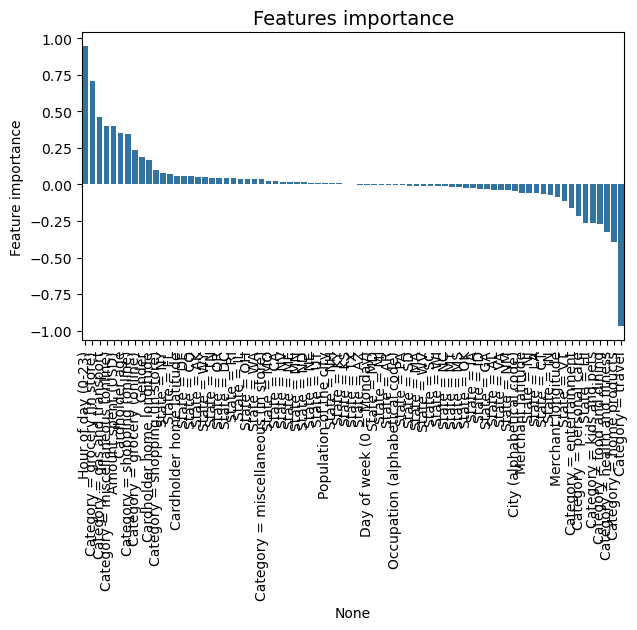

In [25]:
tmp = feature_importances = pd.DataFrame(model.coef_.flatten(), index=predictors, columns=['Feature importance'])
tmp = tmp.sort_values(by='Feature importance',ascending=False)

plt.figure(figsize = (7,4))
plt.title('Features importance',fontsize=14)
s = sns.barplot(x=tmp.index,y='Feature importance',data=tmp)
s.set_xticklabels(s.get_xticklabels(),rotation=90)
plt.show()

##### confusion matrix

In [26]:
cm = pd.crosstab(valid_df[target].values, preds, rownames=['Actual'], colnames=['Predicted'])
display(HTML(cm.to_html(index=True,header=True)))

fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True, ax=ax1,
            linewidths=.2, linecolor="Darkblue", cmap="Blues")

Predicted,0,1
Actual,,
0,206217,83
1,1163,8


<Axes: xlabel='Predicted', ylabel='Actual'>

##### score

In [27]:
recall = recall_score(valid_df[target].values, preds, average='binary')
print(f"Recall Score of {model_name} = ", recall)

precision = precision_score(valid_df[target].values, preds, average='binary')
print(f"Precision Score of {model_name} = ", precision)

specificity = recall_score(valid_df[target].values, preds, pos_label=0)
print(f"Specificity Score of {model_name} = ", specificity)

f1 = f1_score(valid_df[target].values, preds)
print(f"F1 Score of {model_name} = ", f1)

Recall Score of Logistic Regression =  0.006831767719897523
Precision Score of Logistic Regression =  0.08791208791208792
Specificity Score of Logistic Regression =  0.9995976732913233
F1 Score of Logistic Regression =  0.012678288431061807


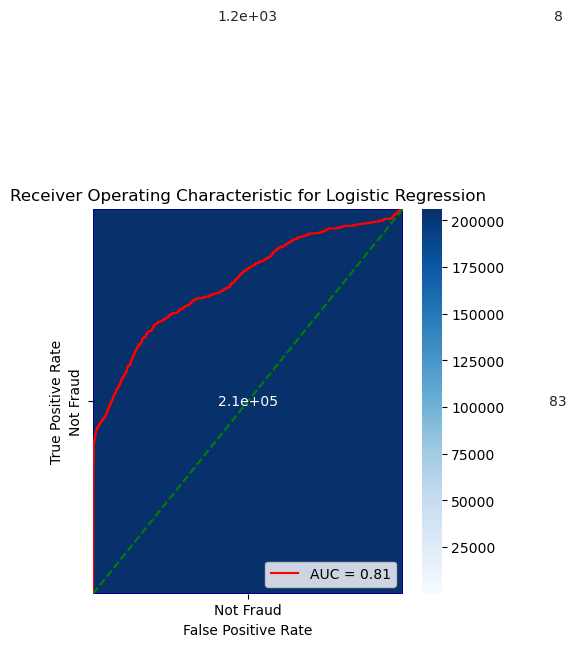

In [28]:
fpr, tpr, threshold = metrics.roc_curve(valid_df[target].values, preds_proba)
roc_auc = metrics.auc(fpr, tpr)

plt.title(f"Receiver Operating Characteristic for {model_name}")
plt.plot(fpr, tpr, 'r', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'g--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [29]:
AUC = roc_auc_score(valid_df[target], preds_proba)
AUCPR = average_precision_score(valid_df[target], preds_proba)

print(f"AUC of {model_name} = ", AUC)
print(f"AUC-PR of {model_name} = ", AUCPR)

AUC, AUCPR


AUC of Logistic Regression =  0.8085362159441305
AUC-PR of Logistic Regression =  0.21788930972598047


(np.float64(0.8085362159441305), np.float64(0.21788930972598047))

In [30]:
# D9: operating point at the ALERT_RATE investigation budget
score_at_budget(model_name, valid_df[target].values, preds_proba)

budget_df


Logistic Regression: threshold 0.0641, alert rate 0.50%, recall 0.3843, precision 0.4339


,metric\model,Logistic Regression
0,Operating threshold,0.064098
1,Alert rate,0.004998
2,Recall (budget),0.384287
3,Precision (budget),0.433944
4,F1 (budget),0.407609
5,MCC (budget),0.405206


In [31]:
# V24: register Logistic Regression for the one-time test evaluation
assert model_name == "Logistic Regression", model_name
fitted_models[model_name] = lambda d, m=model, s=scaler: m.predict_proba(s.transform(d[predictors]))[:, 1]
valid_thresholds[model_name] = budget_threshold(preds_proba)


In [32]:
MCC = matthews_corrcoef(valid_df[target].values, preds)
print(f"Matthew's Correlation Coefficient of {model_name} = ", MCC)

bcr = (recall+specificity)/2
print(f"Balanced Classification Rate of {model_name} = ", bcr)

Matthew's Correlation Coefficient of Logistic Regression =  0.02300367093339222
Balanced Classification Rate of Logistic Regression =  0.5032147205056104


In [33]:
result_df[model_name] = [recall, precision, specificity, f1, AUC, AUCPR, MCC, bcr]

result_df

,metric\model,Logistic Regression
0,Recall,0.006832
1,Precision,0.087912
2,Specificity,0.999598
3,F1 Score,0.012678
4,AUC,0.808536
5,AUC-PR,0.217889
6,MCC,0.023004
7,Balanced Classification Rate,0.503215


#### Decision Tree

In [34]:
# D8: hyperparameters from the TUNED table (after the predictor list).
# The submitted tree was grown unpruned; tuned, it is the interpretability
# result of the revision (Revision_Phase2_Results_V03.md).
clf = DecisionTreeClassifier(**PARAMS["Decision Tree"], random_state=RANDOM_STATE)
model_name = "Decision Tree"


In [35]:
clf.fit(train_df[predictors], train_df[target].values)

DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, min_samples_split=50,
                       random_state=1200)

In [36]:
train_df

,Time difference from the first transaction,Amount spent (USD),Population of the city,Cardholder home latitude,Cardholder home longitude,Merchant latitude,Merchant longitude,Gender,Cardholder age,Hour of day (0-23),Day of week (0 = Monday),Category = entertainment,Category = food and dining,Category = gas and transport,Category = grocery (online),Category = grocery (in store),Category = health and fitness,Category = home products,Category = kids and pets,Category = miscellaneous (online),Category = miscellaneous (in store),Category = personal care,Category = shopping (online),Category = shopping (in store),Category = travel,State = AK,State = AL,State = AR,State = AZ,State = CA,State = CO,State = CT,State = DC,State = DE,State = FL,State = GA,State = HI,State = IA,State = ID,State = IL,State = IN,State = KS,State = KY,State = LA,State = MA,State = MD,State = ME,State = MI,State = MN,State = MO,State = MS,State = MT,State = NC,State = ND,State = NE,State = NH,State = NJ,State = NM,State = NV,State = NY,State = OH,State = OK,State = OR,State = PA,State = RI,State = SC,State = SD,State = TN,State = TX,State = UT,State = VA,State = VT,State = WA,State = WI,State = WV,State = WY,City (alphabetical code),Occupation (alphabetical code),is_fraud
0,0,4.97,3495,36.0788,-81.1781,36.011293,-82.048315,0,30.814511,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,526,370,0
1,0,107.23,149,48.8878,-118.2105,49.159047,-118.186462,0,40.531143,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,612,428,0
2,0,220.11,4154,42.1808,-112.2620,43.150704,-112.154481,1,56.950034,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,468,307,0
3,0,45.00,1939,46.2306,-112.1138,47.034331,-112.561071,1,51.969884,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,84,328,0
4,0,41.96,99,38.4207,-79.4629,38.674999,-78.632459,1,32.763860,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,216,116,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
829915,8249,60.53,2408,32.5486,-80.3070,32.535318,-79.531696,0,22.431211,17,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,237,404,0
829916,8249,9.73,2836,31.1569,-94.3871,30.555086,-94.017810,1,34.017796,17,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,893,126,0
829917,8249,1.29,761,46.5901,-117.1692,46.062388,-117.212680,0,76.446270,17,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,167,76,0
829918,8249,18.21,4154,42.1808,-112.2620,42.389324,-112.014036,1,57.889117,17,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,468,307,0


In [37]:
preds = clf.predict(valid_df[predictors])
preds_proba = clf.predict_proba(valid_df[predictors])[:, 1] # Phase 1: needed for a real ROC-AUC and AUC-PR

##### tree plot




In [38]:
plt.figure(figsize=(200, 30))

plot_tree(clf, 
filled=True,
max_depth=6,
label='root',
feature_names = predictors,
class_names = ["Not fraud", "Fraud"],
rounded=True,
impurity=False,
fontsize=10
)

plt.show()

##### feature importance

/var/folders/7m/vfsyrlbj4rz0cgt75fszf3jr0000gr/T/ipykernel_20047/1428594667.py:6: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



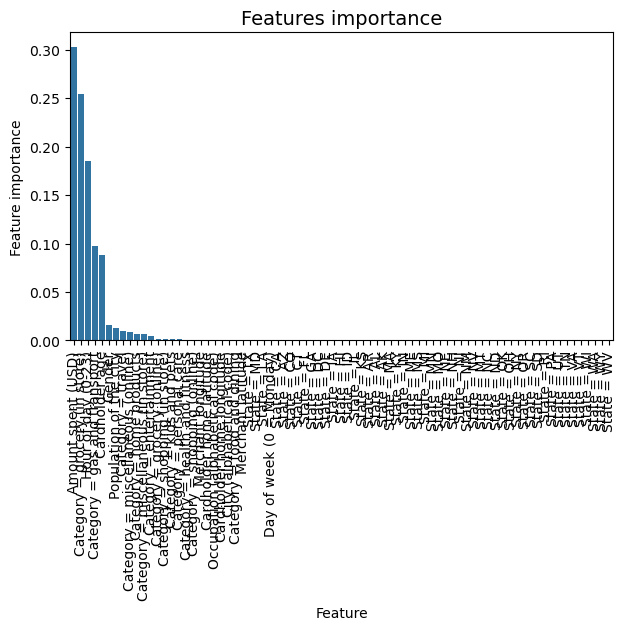

In [39]:
tmp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_})
tmp = tmp.sort_values(by='Feature importance',ascending=False)
plt.figure(figsize = (7,4))
plt.title('Features importance',fontsize=14)
s = sns.barplot(x='Feature',y='Feature importance',data=tmp)
s.set_xticklabels(s.get_xticklabels(),rotation=90)
plt.show()

In [40]:
feature_imp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_})

feature_imp

,Feature,Feature importance
0,Amount spent (USD),0.302582
1,Population of the city,0.012464
2,Cardholder home latitude,0.000449
3,Cardholder home longitude,0.000190
4,Merchant latitude,0.000075
...,...,...
72,State = WI,0.000000
73,State = WV,0.000000
74,State = WY,0.000000
75,City (alphabetical code),0.000179


##### SHAP

In [41]:
# Obtain random entries and get SHAP value

nonFraud_index = list(valid_df.loc[valid_df[target]==0].index) # obtain non Fraud index
random.seed(RANDOM_STATE) # set random state number
random_nonFraud = np.array(random.sample(nonFraud_index, 1000)) # obtain indeces from non Fraud

Fraud_index = list(valid_df.loc[valid_df[target]==1].index) # obtain Fraud index
random.seed(RANDOM_STATE) # set random state number
random_Fraud = np.array(random.sample(Fraud_index, 1000)) # obtain indeces from Fraud

random_index = np.concatenate((random_nonFraud, random_Fraud), axis=0)
random.shuffle(random_index)

df_random = valid_df.loc[random_index,:] # df of randomly selected data

df_random['is_fraud'].value_counts()

is_fraud
0    1000
1    1000
Name: count, dtype: int64

(2000, 77, 2)
SHAP beeswarm, both Non fraud and fraud, Decision Tree:

Amount spent (USD): 	 minium: 1.02, median: 96.42500000000001, max: 1294.83
Population of the city: 	 minium: 23, median: 2607.0, max: 2906700
Cardholder home latitude: 	 minium: 20.0271, median: 39.2501, max: 64.7556
Cardholder home longitude: 	 minium: -165.6723, median: -88.3319, max: -67.9503
Merchant latitude: 	 minium: 19.425114, median: 39.124988, max: 63.833601
Merchant longitude: 	 minium: -165.714379, median: -88.49093450000001, max: -68.030168
Gender: 	 minium: 0, median: 0.0, max: 1
Cardholder age: 	 minium: 14.869267624914444, median: 45.07597535934291, max: 95.16495550992472
Hour of day (0-23): 	 minium: 0, median: 15.0, max: 23
Day of week (0 = Monday): 	 minium: 0, median: 4.0, max: 6
Category = entertainment: 	 minium: 0, median: 0.0, max: 1
Category = food and dining: 	 minium: 0, median: 0.0, max: 1
Category = gas and transport: 	 minium: 0, median: 0.0, max: 1
Category = grocery (online): 	 miniu

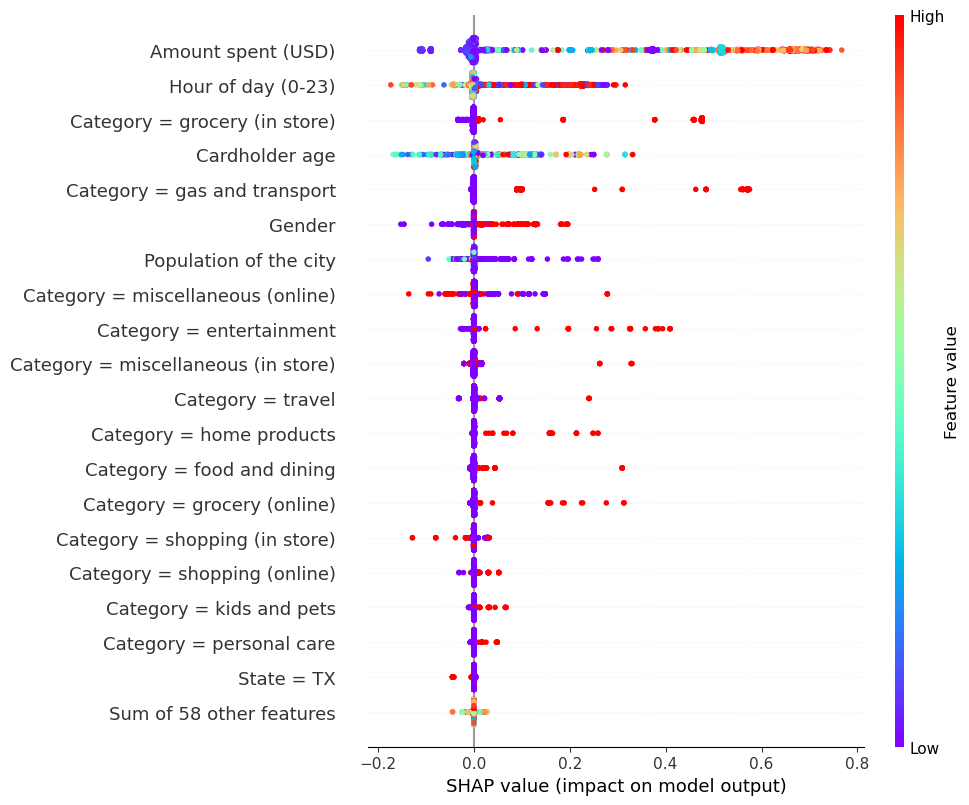

In [42]:
# SHAP beeswarm for random samples (class ratio is aprox. same with original)

explainer = shap.TreeExplainer(clf)
X = df_random[predictors] # obtain selected random entries for shap

shap_values = explainer(X)

print(shap_values.shape)

exp = shap.Explanation(shap_values.values[:,:,1], 
                  shap_values.base_values[:,1], 
                  data=X.values, 
                  feature_names=X.columns)
idx = 0

print(f"SHAP beeswarm, both Non fraud and fraud, {model_name}:\n")

for f in predictors:
    data = df_random[f]
    print(f"{f}: \t minium: {data.min()}, median: {data.median()}, max: {data.max()}")
    
shap.plots.beeswarm(exp, max_display=20, color=plt.get_cmap("rainbow"))

In [43]:
# SHAP force graph

shap.initjs()
shap.plots.force(explainer.expected_value[0], exp[:].values, feature_names=predictors)

##### LIME

In [44]:
print(f"LIME, {model_name}:")

start = datetime.now()
print("start:", start)

warnings.filterwarnings('ignore') # disable Python warning for this cell

# V25: seeded -- without random_state LIME draws different perturbation samples each
# run, so the averaged contributions changed between otherwise identical runs
# (by up to 0.0045; the top-ranked conditions were stable).
explainer = lime.lime_tabular.LimeTabularExplainer(train_df[predictors].values,
random_state=RANDOM_STATE,
feature_names=predictors,
class_names=['class_0', 'class_1'],
discretize_continuous=True)

print("Baseline probability:", valid_df[target].values.mean()) # obtain baseline probability

n = 500
contributions_list = []
for i in range(n):
    exp = explainer.explain_instance(df_random[predictors].iloc[i], clf.predict_proba, num_features=len(predictors), num_samples=2000)
    contributions = exp.as_list()  # [(feature1, value1), (feature2, value2), ...]
    contributions_list.extend(contributions)

contributions_dict = {}
for feature, value in contributions_list:
    if feature not in contributions_dict:
        contributions_dict[feature] = []
    contributions_dict[feature].append(value)

for k, v in contributions_dict.items():
    average = np.mean(v)
    contributions_dict[k] = average

df_lime = pd.DataFrame.from_dict(contributions_dict, orient='index')

df_lime.to_csv(f"result_csv/LIME_{model_name}_{TAG}.csv")

end = datetime.now()
print("end:", end)
print("time required:", end-start)

df_lime

LIME, Decision Tree:
start: 2026-10-13 13:51:06.767132


Baseline probability: 0.005644162316661124


end: 2026-10-13 13:51:58.536979
time required: 0:00:51.769847


,0
Category = gas and transport <= 0.00,-0.261616
State = CT <= 0.00,-0.003311
State = ND <= 0.00,0.000960
Category = grocery (in store) <= 0.00,-0.131062
State = DC <= 0.00,-0.001112
...,...
State = SD > 0.00,0.008861
State = VT > 0.00,0.013070
State = NH > 0.00,0.058089
State = CT > 0.00,0.076753


##### confusion matrix

In [45]:
cm = pd.crosstab(valid_df[target].values, preds, rownames=['Actual'], colnames=['Predicted'])
display(HTML(cm.to_html(index=True,header=True)))

fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True, ax=ax1,
            linewidths=.2, linecolor="Darkblue", cmap="Blues")

Predicted,0,1
Actual,,
0,206228,72
1,222,949


<Axes: xlabel='Predicted', ylabel='Actual'>

##### score 

In [46]:
recall = recall_score(valid_df[target].values, preds, average='binary')
print(f"Recall Score of {model_name} = ", recall)

precision = precision_score(valid_df[target].values, preds, average='binary')
print(f"Precision Score of {model_name} = ", precision)

specificity = recall_score(valid_df[target].values, preds, pos_label=0)
print(f"Specificity Score of {model_name} = ", specificity)

f1 = f1_score(valid_df[target].values, preds)
print(f"F1 Score of {model_name} = ", f1)    

Recall Score of Decision Tree =  0.8104184457728437
Precision Score of Decision Tree =  0.9294809010773751
Specificity Score of Decision Tree =  0.9996509936984973
F1 Score of Decision Tree =  0.8658759124087592


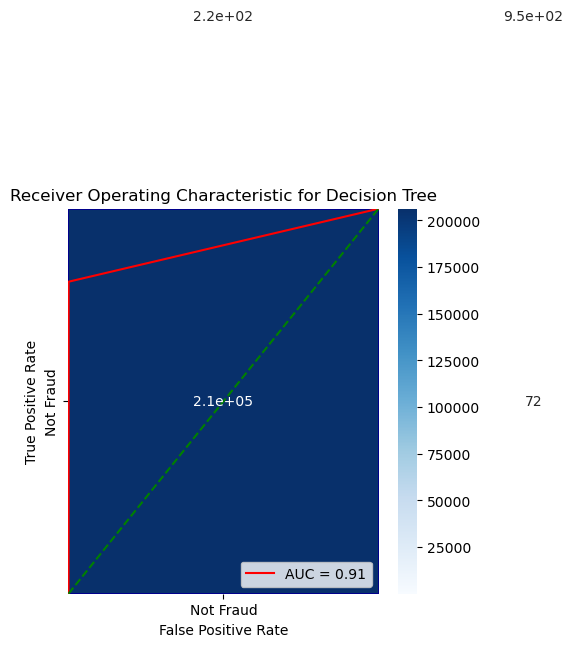

In [47]:
fpr, tpr, threshold = metrics.roc_curve(valid_df[target].values, preds)
roc_auc = metrics.auc(fpr, tpr)

plt.title(f"Receiver Operating Characteristic for {model_name}")
plt.plot(fpr, tpr, 'r', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'g--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [48]:
AUC = roc_auc_score(valid_df[target].values, preds_proba)
AUCPR = average_precision_score(valid_df[target].values, preds_proba)

print(f"AUC of {model_name} = ", AUC)
print(f"AUC-PR of {model_name} = ", AUCPR)

AUC, AUCPR


AUC of Decision Tree =  0.9832730331036899
AUC-PR of Decision Tree =  0.8948386644522701


(np.float64(0.9832730331036899), np.float64(0.8948386644522701))

In [49]:
# D9: operating point at the ALERT_RATE investigation budget
score_at_budget(model_name, valid_df[target].values, preds_proba)

budget_df


Decision Tree: threshold 0.5000, alert rate 0.50%, recall 0.8215, precision 0.9250


,metric\model,Logistic Regression,Decision Tree
0,Operating threshold,0.064098,0.500000
1,Alert rate,0.004998,0.005013
2,Recall (budget),0.384287,0.821520
3,Precision (budget),0.433944,0.925000
4,F1 (budget),0.407609,0.870194
5,MCC (budget),0.405206,0.871048


In [50]:
# V24: register Decision Tree for the one-time test evaluation
assert model_name == "Decision Tree", model_name
fitted_models[model_name] = lambda d, m=clf: m.predict_proba(d[predictors])[:, 1]
valid_thresholds[model_name] = budget_threshold(preds_proba)


In [51]:
MCC = matthews_corrcoef(valid_df[target].values, preds)
print(f"Matthew's Correlation Coefficient of {model_name} = ", MCC)

bcr = (recall+specificity)/2
print(f"Balanced Classification Rate of {model_name} = ", bcr)

Matthew's Correlation Coefficient of Decision Tree =  0.8672214180563037
Balanced Classification Rate of Decision Tree =  0.9050347197356705


##### Result df

In [52]:
result_df[model_name] = [recall, precision, specificity, f1, AUC, AUCPR, MCC, bcr]

result_df

,metric\model,Logistic Regression,Decision Tree
0,Recall,0.006832,0.810418
1,Precision,0.087912,0.929481
2,Specificity,0.999598,0.999651
3,F1 Score,0.012678,0.865876
4,AUC,0.808536,0.983273
5,AUC-PR,0.217889,0.894839
6,MCC,0.023004,0.867221
7,Balanced Classification Rate,0.503215,0.905035


In [53]:
feature_df[model_name] = feature_imp['Feature importance']

feature_df

,feature\model,Decision Tree
0,Amount spent (USD),0.302582
1,Population of the city,0.012464
2,Cardholder home latitude,0.000449
3,Cardholder home longitude,0.000190
4,Merchant latitude,0.000075
...,...,...
72,State = WI,0.000000
73,State = WV,0.000000
74,State = WY,0.000000
75,City (alphabetical code),0.000179


#### Random Forest

In [54]:
# D8: hyperparameters from the TUNED table (after the predictor list).
clf = RandomForestClassifier(**PARAMS["Random Forest"], n_jobs=NO_JOBS,
                             random_state=RANDOM_STATE, verbose=False)
model_name = "Random Forest"


In [55]:
clf.fit(train_df[predictors], train_df[target].values)

RandomForestClassifier(max_depth=16, max_features=0.5, n_estimators=400,
                       n_jobs=4, random_state=1200, verbose=False)

In [56]:
preds = clf.predict(valid_df[predictors])
preds_proba = clf.predict_proba(valid_df[predictors])[:, 1] # Phase 1: needed for a real ROC-AUC and AUC-PR

##### feature importance

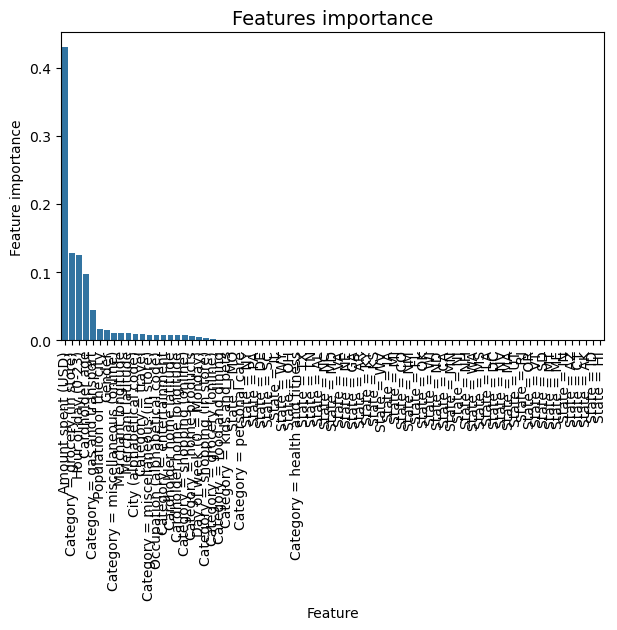

In [57]:
tmp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_})
tmp = tmp.sort_values(by='Feature importance',ascending=False)
plt.figure(figsize = (7,4))
plt.title('Features importance',fontsize=14)
s = sns.barplot(x='Feature',y='Feature importance',data=tmp)
s.set_xticklabels(s.get_xticklabels(),rotation=90)
plt.show()

In [58]:
feature_imp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_})

feature_imp

,Feature,Feature importance
0,Amount spent (USD),0.430285
1,Population of the city,0.017179
2,Cardholder home latitude,0.007860
3,Cardholder home longitude,0.007491
4,Merchant latitude,0.011458
...,...,...
72,State = WI,0.000328
73,State = WV,0.000413
74,State = WY,0.000680
75,City (alphabetical code),0.009160


##### SHAP

(2000, 77, 2)
SHAP beeswarm, both Non fraud and fraud, Random Forest:

Amount spent (USD): 	 minium: 1.02, median: 96.42500000000001, max: 1294.83
Population of the city: 	 minium: 23, median: 2607.0, max: 2906700
Cardholder home latitude: 	 minium: 20.0271, median: 39.2501, max: 64.7556
Cardholder home longitude: 	 minium: -165.6723, median: -88.3319, max: -67.9503
Merchant latitude: 	 minium: 19.425114, median: 39.124988, max: 63.833601
Merchant longitude: 	 minium: -165.714379, median: -88.49093450000001, max: -68.030168
Gender: 	 minium: 0, median: 0.0, max: 1
Cardholder age: 	 minium: 14.869267624914444, median: 45.07597535934291, max: 95.16495550992472
Hour of day (0-23): 	 minium: 0, median: 15.0, max: 23
Day of week (0 = Monday): 	 minium: 0, median: 4.0, max: 6
Category = entertainment: 	 minium: 0, median: 0.0, max: 1
Category = food and dining: 	 minium: 0, median: 0.0, max: 1
Category = gas and transport: 	 minium: 0, median: 0.0, max: 1
Category = grocery (online): 	 miniu

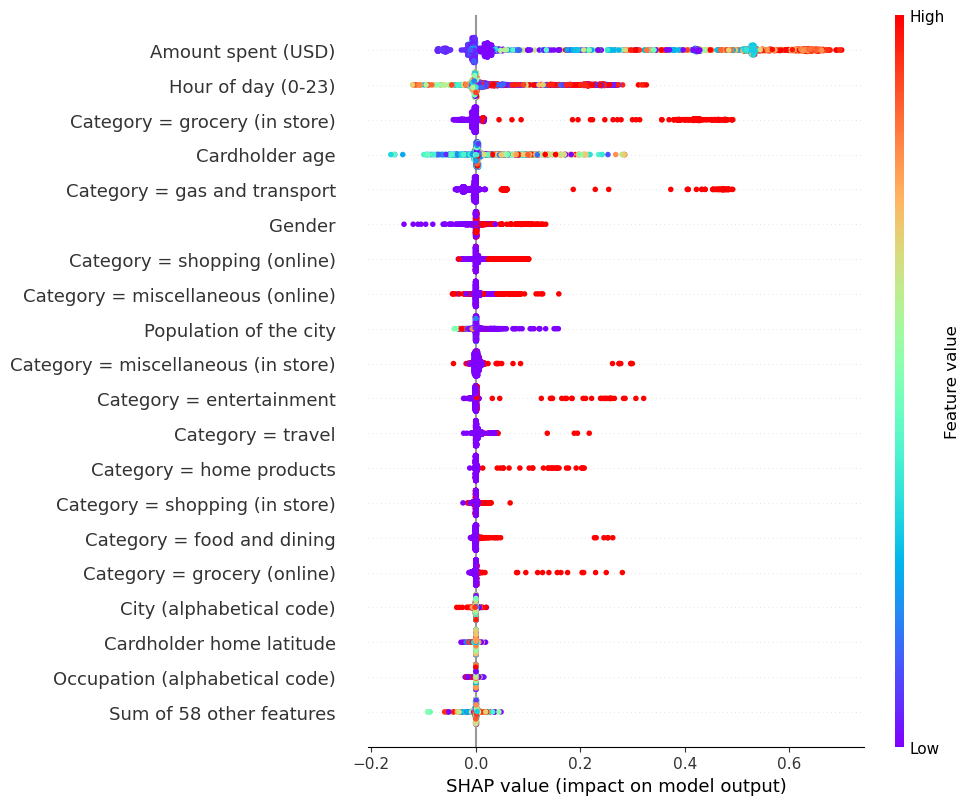

In [59]:
# SHAP beeswarm for random samples (class ratio is aprox. same with original)

explainer = shap.TreeExplainer(clf)
X = df_random[predictors] # obtain selected random entries for shap

shap_values = explainer(X)

print(shap_values.shape)

exp = shap.Explanation(shap_values.values[:,:,1], 
                  shap_values.base_values[:,1], 
                  data=X.values, 
                  feature_names=X.columns)
idx = 0

print(f"SHAP beeswarm, both Non fraud and fraud, {model_name}:\n")

for f in predictors:
    data = df_random[f]
    print(f"{f}: \t minium: {data.min()}, median: {data.median()}, max: {data.max()}")
    
shap.plots.beeswarm(exp, max_display=20, color=plt.get_cmap("rainbow"))

In [60]:
# SHAP force graph

shap.initjs()
shap.plots.force(explainer.expected_value[0], exp[:].values, feature_names=predictors)

##### LIME

In [61]:
print(f"LIME, {model_name}:")

start = datetime.now()
print("start:", start)

warnings.filterwarnings('ignore') # disable Python warning for this cell

# V25: seeded -- without random_state LIME draws different perturbation samples each
# run, so the averaged contributions changed between otherwise identical runs
# (by up to 0.0045; the top-ranked conditions were stable).
explainer = lime.lime_tabular.LimeTabularExplainer(train_df[predictors].values,
random_state=RANDOM_STATE,
feature_names=predictors,
class_names=['class_0', 'class_1'],
discretize_continuous=True)

print("Baseline probability:", valid_df[target].values.mean()) # obtain baseline probability

n = 500
contributions_list = []
for i in range(n):
    exp = explainer.explain_instance(df_random[predictors].iloc[i], clf.predict_proba, num_features=len(predictors), num_samples=2000)
    contributions = exp.as_list()  # [(feature1, value1), (feature2, value2), ...]
    contributions_list.extend(contributions)

contributions_dict = {}
for feature, value in contributions_list:
    if feature not in contributions_dict:
        contributions_dict[feature] = []
    contributions_dict[feature].append(value)

for k, v in contributions_dict.items():
    average = np.mean(v)
    contributions_dict[k] = average

df_lime = pd.DataFrame.from_dict(contributions_dict, orient='index')

df_lime.to_csv(f"result_csv/LIME_{model_name}_{TAG}.csv")

end = datetime.now()
print("end:", end)
print("time required:", end-start)

df_lime

LIME, Random Forest:
start: 2026-10-13 14:07:23.395035


Baseline probability: 0.005644162316661124


end: 2026-10-13 14:08:59.339230
time required: 0:01:35.944195


,0
Category = gas and transport <= 0.00,-0.235992
State = CT <= 0.00,-0.003177
Category = grocery (in store) <= 0.00,-0.143187
State = ND <= 0.00,0.000197
State = AZ > 0.00,0.059635
...,...
State = SD > 0.00,0.009940
State = VT > 0.00,0.007013
State = NH > 0.00,0.052541
State = CT > 0.00,0.058121


##### confusion matrix

In [62]:
cm = pd.crosstab(valid_df[target].values, preds, rownames=['Actual'], colnames=['Predicted'])
display(HTML(cm.to_html(index=True,header=True)))

fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True, ax=ax1,
            linewidths=.2, linecolor="Darkblue", cmap="Blues")

Predicted,0,1
Actual,,
0,206258,42
1,233,938


<Axes: xlabel='Predicted', ylabel='Actual'>

##### score 

In [63]:
recall = recall_score(valid_df[target].values, preds, average='binary')
print(f"Recall Score of {model_name} = ", recall)

precision = precision_score(valid_df[target].values, preds, average='binary')
print(f"Precision Score of {model_name} = ", precision)

specificity = recall_score(valid_df[target].values, preds, pos_label=0)
print(f"Specificity Score of {model_name} = ", specificity)

f1 = f1_score(valid_df[target].values, preds)
print(f"F1 Score of {model_name} = ", f1) 

Recall Score of Random Forest =  0.8010247651579846
Precision Score of Random Forest =  0.9571428571428572
Specificity Score of Random Forest =  0.9997964129907901
F1 Score of Random Forest =  0.8721524872152487


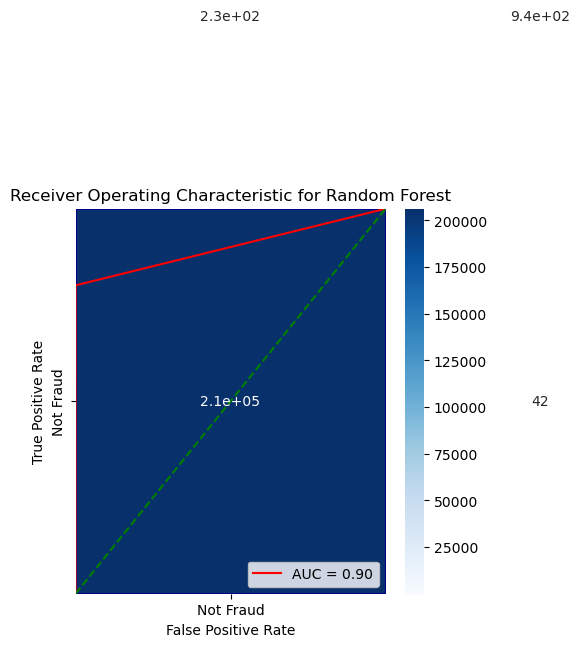

In [64]:
fpr, tpr, threshold = metrics.roc_curve(valid_df[target].values, preds)
roc_auc = metrics.auc(fpr, tpr)

plt.title(f"Receiver Operating Characteristic for {model_name}")
plt.plot(fpr, tpr, 'r', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'g--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [65]:
AUC = roc_auc_score(valid_df[target].values, preds_proba)
AUCPR = average_precision_score(valid_df[target].values, preds_proba)

print(f"AUC of {model_name} = ", AUC)
print(f"AUC-PR of {model_name} = ", AUCPR)

AUC, AUCPR


AUC of Random Forest =  0.9970877541060357
AUC-PR of Random Forest =  0.9229170758678741


(np.float64(0.9970877541060357), np.float64(0.9229170758678741))

In [66]:
# D9: operating point at the ALERT_RATE investigation budget
score_at_budget(model_name, valid_df[target].values, preds_proba)

budget_df


Random Forest: threshold 0.3468, alert rate 0.50%, recall 0.8275, precision 0.9344


,metric\model,Logistic Regression,Decision Tree,Random Forest
0,Operating threshold,0.064098,0.500000,0.346805
1,Alert rate,0.004998,0.005013,0.004998
2,Recall (budget),0.384287,0.821520,0.827498
3,Precision (budget),0.433944,0.925000,0.934426
4,F1 (budget),0.407609,0.870194,0.877717
5,MCC (budget),0.405206,0.871048,0.878703


In [67]:
# V24: register Random Forest for the one-time test evaluation
assert model_name == "Random Forest", model_name
fitted_models[model_name] = lambda d, m=clf: m.predict_proba(d[predictors])[:, 1]
valid_thresholds[model_name] = budget_threshold(preds_proba)


In [68]:
MCC = matthews_corrcoef(valid_df[target].values, preds)
print(f"Matthew's Correlation Coefficient of {model_name} = ", MCC)

bcr = (recall+specificity)/2
print(f"Balanced Classification Rate of {model_name} = ", bcr)

Matthew's Correlation Coefficient of Random Forest =  0.8749837947829912
Balanced Classification Rate of Random Forest =  0.9004105890743874


##### Result df

In [69]:
result_df[model_name] = [recall, precision, specificity, f1, AUC, AUCPR, MCC, bcr]

result_df

,metric\model,Logistic Regression,Decision Tree,Random Forest
0,Recall,0.006832,0.810418,0.801025
1,Precision,0.087912,0.929481,0.957143
2,Specificity,0.999598,0.999651,0.999796
3,F1 Score,0.012678,0.865876,0.872152
4,AUC,0.808536,0.983273,0.997088
5,AUC-PR,0.217889,0.894839,0.922917
6,MCC,0.023004,0.867221,0.874984
7,Balanced Classification Rate,0.503215,0.905035,0.900411


In [70]:
feature_df[model_name] = feature_imp['Feature importance']

feature_df

,feature\model,Decision Tree,Random Forest
0,Amount spent (USD),0.302582,0.430285
1,Population of the city,0.012464,0.017179
2,Cardholder home latitude,0.000449,0.007860
3,Cardholder home longitude,0.000190,0.007491
4,Merchant latitude,0.000075,0.011458
...,...,...,...
72,State = WI,0.000000,0.000328
73,State = WV,0.000000,0.000413
74,State = WY,0.000000,0.000680
75,City (alphabetical code),0.000179,0.009160


#### AdaBoost

In [71]:
# D8: hyperparameters from the TUNED table (after the predictor list).
clf = AdaBoostClassifier(**PARAMS["AdaBoost"], algorithm='SAMME', random_state=RANDOM_STATE)

model_name = "AdaBoost"


In [72]:
class_weights = compute_class_weight('balanced', classes=np.unique(train_df[target].values), y=train_df[target].values)
class_weight_dict = dict(enumerate(class_weights))

class_weight_dict

{0: np.float64(0.5029068393439523), 1: np.float64(86.5040650406504)}

In [73]:
sample_weight = np.array([class_weight_dict[class_label] for class_label in train_df[target].values])

In [74]:
clf.fit(train_df[predictors], train_df[target].values, sample_weight=sample_weight)

AdaBoostClassifier(algorithm='SAMME', learning_rate=0.8198461683333294,
                   n_estimators=200, random_state=1200)

In [75]:
preds = clf.predict(valid_df[predictors])
preds_proba = clf.predict_proba(valid_df[predictors])[:, 1] # Phase 1: needed for a real ROC-AUC and AUC-PR

##### feature importance

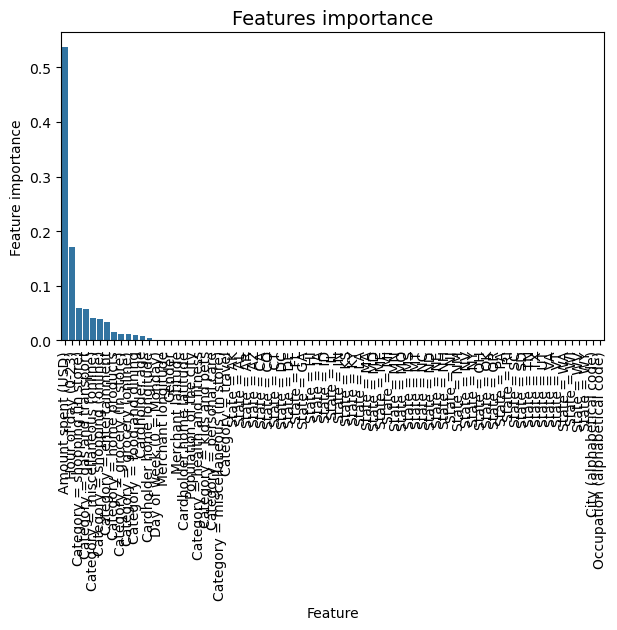

In [76]:
tmp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_})
tmp = tmp.sort_values(by='Feature importance',ascending=False)
plt.figure(figsize = (7,4))
plt.title('Features importance',fontsize=14)
s = sns.barplot(x='Feature',y='Feature importance',data=tmp)
s.set_xticklabels(s.get_xticklabels(),rotation=90)
plt.show()

##### confusion matrix

In [77]:
cm = pd.crosstab(valid_df[target].values, preds, rownames=['Actual'], colnames=['Predicted'])
display(HTML(cm.to_html(index=True,header=True)))

fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True,ax=ax1,
            linewidths=.2,linecolor="Darkblue", cmap="Blues")

Predicted,0,1
Actual,,
0,196451,9849
1,67,1104


<Axes: xlabel='Predicted', ylabel='Actual'>

##### score

In [78]:
recall = recall_score(valid_df[target].values, preds, average='binary')
print(f"Recall Score of {model_name} = ", recall)

precision = precision_score(valid_df[target].values, preds, average='binary')
print(f"Precision Score of {model_name} = ", precision)

specificity = recall_score(valid_df[target].values, preds, pos_label=0)
print(f"Specificity Score of {model_name} = ", specificity)

f1 = f1_score(valid_df[target].values, preds)
print("F1 Score of AdaBoost = ", f1)

Recall Score of AdaBoost =  0.9427839453458582
Precision Score of AdaBoost =  0.10079430293070392
Specificity Score of AdaBoost =  0.9522588463402811
F1 Score of AdaBoost =  0.18211811283404816


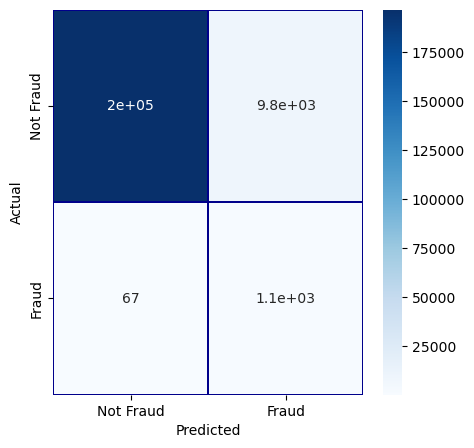

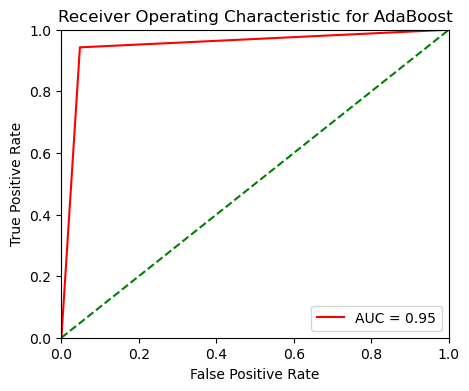

In [79]:
fpr, tpr, threshold = metrics.roc_curve(valid_df[target].values, preds)
roc_auc = metrics.auc(fpr, tpr)

plt.figure(figsize = (5,4))
plt.title('Receiver Operating Characteristic for AdaBoost')
plt.plot(fpr, tpr, 'r', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'g--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [80]:
AUC = roc_auc_score(valid_df[target].values, preds_proba)
AUCPR = average_precision_score(valid_df[target].values, preds_proba)

print(f"AUC of {model_name} = ", AUC)
print(f"AUC-PR of {model_name} = ", AUCPR)

AUC, AUCPR


AUC of AdaBoost =  0.9865437832942086
AUC-PR of AdaBoost =  0.5582919187995394


(np.float64(0.9865437832942086), np.float64(0.5582919187995394))

In [81]:
# D9: operating point at the ALERT_RATE investigation budget
score_at_budget(model_name, valid_df[target].values, preds_proba)

budget_df


AdaBoost: threshold 0.5990, alert rate 0.52%, recall 0.5124, precision 0.5592


,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost
0,Operating threshold,0.064098,0.500000,0.346805,0.599031
1,Alert rate,0.004998,0.005013,0.004998,0.005172
2,Recall (budget),0.384287,0.821520,0.827498,0.512383
3,Precision (budget),0.433944,0.925000,0.934426,0.559180
4,F1 (budget),0.407609,0.870194,0.877717,0.534759
5,MCC (budget),0.405206,0.871048,0.878703,0.532748


In [82]:
# V24: register AdaBoost for the one-time test evaluation
assert model_name == "AdaBoost", model_name
fitted_models[model_name] = lambda d, m=clf: m.predict_proba(d[predictors])[:, 1]
valid_thresholds[model_name] = budget_threshold(preds_proba)


In [83]:
MCC = matthews_corrcoef(valid_df[target].values, preds)
print(f"Matthew's Correlation Coefficient of {model_name} = ", MCC)

bcr = (recall+specificity)/2
print(f"Balanced Classification Rate of {model_name} = ", bcr)

Matthew's Correlation Coefficient of AdaBoost =  0.2998500662815702
Balanced Classification Rate of AdaBoost =  0.9475213958430697


In [84]:
result_df[model_name] = [recall, precision, specificity, f1, AUC, AUCPR, MCC, bcr]

result_df

,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost
0,Recall,0.006832,0.810418,0.801025,0.942784
1,Precision,0.087912,0.929481,0.957143,0.100794
2,Specificity,0.999598,0.999651,0.999796,0.952259
3,F1 Score,0.012678,0.865876,0.872152,0.182118
4,AUC,0.808536,0.983273,0.997088,0.986544
5,AUC-PR,0.217889,0.894839,0.922917,0.558292
6,MCC,0.023004,0.867221,0.874984,0.299850
7,Balanced Classification Rate,0.503215,0.905035,0.900411,0.947521


#### Catboost

In [85]:
# D8: hyperparameters from the TUNED table (after the predictor list).
clf = CatBoostClassifier(**PARAMS["CatBoost"], eval_metric='AUC', random_seed=RANDOM_STATE,
                         od_type='Iter', od_wait=100, metric_period=VERBOSE_EVAL)
model_name = "CatBoost"


In [86]:
clf.fit(train_df[predictors], train_df[target].values,verbose=True)

0:	total: 131ms	remaining: 2m 10s


50:	total: 1.4s	remaining: 26s


100:	total: 2.56s	remaining: 22.8s


150:	total: 3.73s	remaining: 21s


200:	total: 4.93s	remaining: 19.6s


250:	total: 6.12s	remaining: 18.3s


... (12 outputs left out)

900:	total: 21.6s	remaining: 2.38s


950:	total: 22.9s	remaining: 1.18s


999:	total: 24s	remaining: 0us


CatBoostClassifier(bagging_temperature=0.12479937612392289, depth=8, eval_metric='AUC', iterations=1000, l2_leaf_reg=1.0, learning_rate=0.015474590024779264, metric_period=50, od_type='Iter', od_wait=100, random_seed=1200)

In [87]:
preds = clf.predict(valid_df[predictors])
preds_proba = clf.predict_proba(valid_df[predictors])[:, 1] # Phase 1: needed for a real ROC-AUC and AUC-PR

##### feature importance

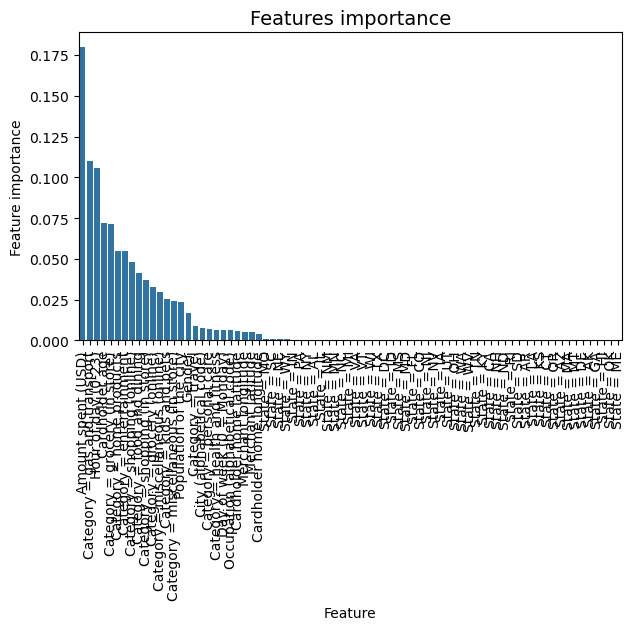

In [88]:
tmp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_/100})
tmp = tmp.sort_values(by='Feature importance',ascending=False)
plt.figure(figsize = (7,4))
plt.title('Features importance',fontsize=14)
s = sns.barplot(x='Feature',y='Feature importance',data=tmp)
s.set_xticklabels(s.get_xticklabels(),rotation=90)
plt.show()

In [89]:
feature_imp = pd.DataFrame({'Feature': predictors, 'Feature importance': clf.feature_importances_})

feature_imp['Feature importance'] = feature_imp['Feature importance'] / 100

feature_imp

,Feature,Feature importance
0,Amount spent (USD),0.179837
1,Population of the city,0.023749
2,Cardholder home latitude,0.005534
3,Cardholder home longitude,0.003897
4,Merchant latitude,0.005280
...,...,...
72,State = WI,0.000183
73,State = WV,0.000051
74,State = WY,0.000602
75,City (alphabetical code),0.007950


##### SHAP

(2000, 77)
SHAP beeswarm, both Non fraud and fraud, CatBoost:

Amount spent (USD): 	 minium: 1.02, median: 96.42500000000001, max: 1294.83
Population of the city: 	 minium: 23, median: 2607.0, max: 2906700
Cardholder home latitude: 	 minium: 20.0271, median: 39.2501, max: 64.7556
Cardholder home longitude: 	 minium: -165.6723, median: -88.3319, max: -67.9503
Merchant latitude: 	 minium: 19.425114, median: 39.124988, max: 63.833601
Merchant longitude: 	 minium: -165.714379, median: -88.49093450000001, max: -68.030168
Gender: 	 minium: 0, median: 0.0, max: 1
Cardholder age: 	 minium: 14.869267624914444, median: 45.07597535934291, max: 95.16495550992472
Hour of day (0-23): 	 minium: 0, median: 15.0, max: 23
Day of week (0 = Monday): 	 minium: 0, median: 4.0, max: 6
Category = entertainment: 	 minium: 0, median: 0.0, max: 1
Category = food and dining: 	 minium: 0, median: 0.0, max: 1
Category = gas and transport: 	 minium: 0, median: 0.0, max: 1
Category = grocery (online): 	 minium: 0, me

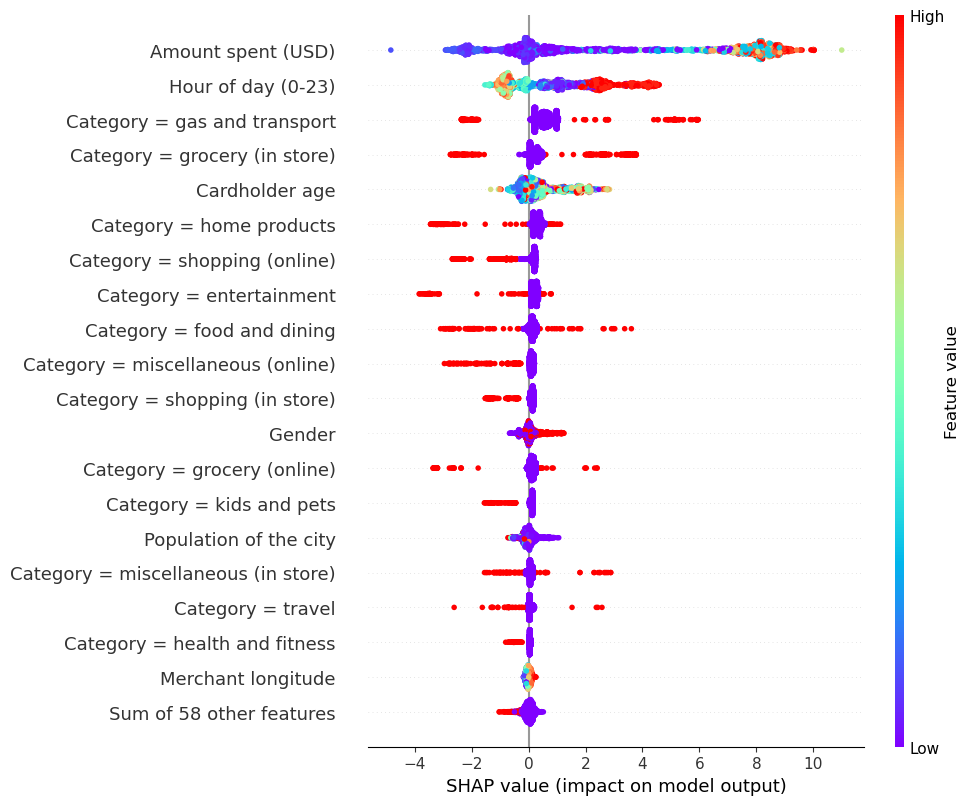

In [90]:
# SHAP beeswarm for random samples (class ratio is aprox. same with original)

# explainer = shap.TreeExplainer(clf, model_output="probability")
explainer = shap.Explainer(clf, link=shap.links.logit)
X = df_random[predictors] # obtain selected random entries for shap

shap_values = explainer(X)

print(shap_values.shape)

print(f"SHAP beeswarm, both Non fraud and fraud, {model_name}:\n")

for f in predictors:
    data = df_random[f]
    print(f"{f}: \t minium: {data.min()}, median: {data.median()}, max: {data.max()}")
    
shap.plots.beeswarm(shap_values, max_display=20, color=plt.get_cmap("rainbow"))

In [91]:
# SHAP force graph

shap.initjs()
shap.plots.force(shap_values, feature_names=predictors)

##### LIME

In [92]:
print(f"LIME, {model_name}:")

start = datetime.now()
print("start:", start)

warnings.filterwarnings('ignore') # disable Python warning for this cell

# V25: seeded -- without random_state LIME draws different perturbation samples each
# run, so the averaged contributions changed between otherwise identical runs
# (by up to 0.0045; the top-ranked conditions were stable).
explainer = lime.lime_tabular.LimeTabularExplainer(train_df[predictors].values,
random_state=RANDOM_STATE,
feature_names=predictors,
class_names=['class_0', 'class_1'],
discretize_continuous=True)

print("Baseline probability:", valid_df[target].values.mean()) # obtain baseline probability

n = 500
contributions_list = []
for i in range(n):
    exp = explainer.explain_instance(df_random[predictors].iloc[i], clf.predict_proba, num_features=len(predictors), num_samples=2000)
    contributions = exp.as_list()  # [(feature1, value1), (feature2, value2), ...]
    contributions_list.extend(contributions)

contributions_dict = {}
for feature, value in contributions_list:
    if feature not in contributions_dict:
        contributions_dict[feature] = []
    contributions_dict[feature].append(value)

for k, v in contributions_dict.items():
    average = np.mean(v)
    contributions_dict[k] = average

df_lime = pd.DataFrame.from_dict(contributions_dict, orient='index')

df_lime.to_csv(f"result_csv/LIME_{model_name}_{TAG}.csv")

end = datetime.now()
print("end:", end)
print("time required:", end-start)

df_lime

LIME, CatBoost:
start: 2026-10-13 14:17:05.059267


Baseline probability: 0.005644162316661124


end: 2026-10-13 14:17:58.040034
time required: 0:00:52.980767


,0
Category = gas and transport <= 0.00,-0.167942
State = AZ > 0.00,0.148220
State = CT <= 0.00,-0.002464
State = HI <= 0.00,0.001588
Category = grocery (in store) <= 0.00,-0.081498
...,...
State = SD > 0.00,0.018541
State = VT > 0.00,-0.025043
State = NH > 0.00,0.062916
State = CT > 0.00,0.105380


##### confusion matrix

In [93]:
cm = pd.crosstab(valid_df[target].values, preds, rownames=['Actual'], colnames=['Predicted'])
display(HTML(cm.to_html(index=True,header=True)))

fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True,ax=ax1,
            linewidths=.2,linecolor="Darkblue", cmap="Blues")

Predicted,0,1
Actual,,
0,206250,50
1,244,927


<Axes: xlabel='Predicted', ylabel='Actual'>

##### score

In [94]:
recall = recall_score(valid_df[target].values, preds, average='binary')
print(f"Recall Score of {model_name} = ", recall)

precision = precision_score(valid_df[target].values, preds, average='binary')
print(f"Precision Score of {model_name} = ", precision)

specificity = recall_score(valid_df[target].values, preds, pos_label=0)
print(f"Specificity Score of {model_name} = ", specificity)

f1 = f1_score(valid_df[target].values, preds)
print(f"F1 Score of {model_name} = ", f1)

Recall Score of CatBoost =  0.7916310845431256
Precision Score of CatBoost =  0.9488229273285568
Specificity Score of CatBoost =  0.9997576345128454
F1 Score of CatBoost =  0.8631284916201117


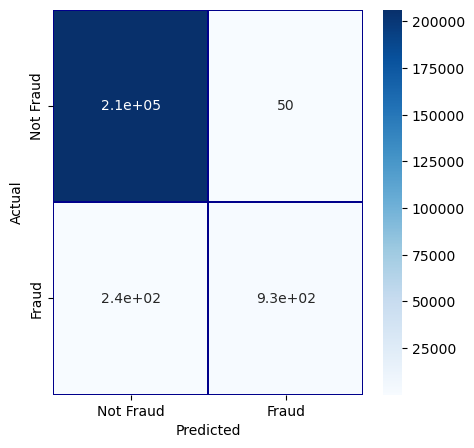

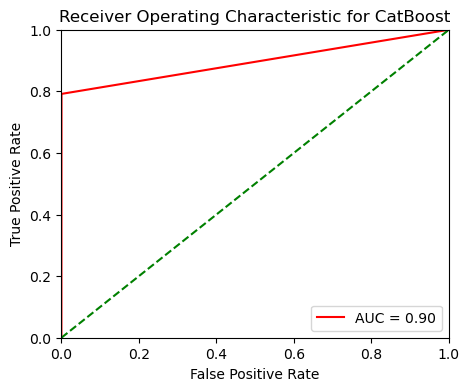

In [95]:
fpr, tpr, threshold = metrics.roc_curve(valid_df[target].values, preds)
roc_auc = metrics.auc(fpr, tpr)

plt.figure(figsize = (5,4))
plt.title('Receiver Operating Characteristic for CatBoost')
plt.plot(fpr, tpr, 'r', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'g--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [96]:
AUC = roc_auc_score(valid_df[target].values, preds_proba)
AUCPR = average_precision_score(valid_df[target].values, preds_proba)

print(f"AUC of {model_name} = ", AUC)
print(f"AUC-PR of {model_name} = ", AUCPR)

AUC, AUCPR


AUC of CatBoost =  0.9975998282951255
AUC-PR of CatBoost =  0.9254647692208822


(np.float64(0.9975998282951255), np.float64(0.9254647692208822))

In [97]:
# D9: operating point at the ALERT_RATE investigation budget
score_at_budget(model_name, valid_df[target].values, preds_proba)

budget_df


CatBoost: threshold 0.3843, alert rate 0.50%, recall 0.8198, precision 0.9257


,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,CatBoost
0,Operating threshold,0.064098,0.500000,0.346805,0.599031,0.384302
1,Alert rate,0.004998,0.005013,0.004998,0.005172,0.004998
2,Recall (budget),0.384287,0.821520,0.827498,0.512383,0.819812
3,Precision (budget),0.433944,0.925000,0.934426,0.559180,0.925747
4,F1 (budget),0.407609,0.870194,0.877717,0.534759,0.869565
5,MCC (budget),0.405206,0.871048,0.878703,0.532748,0.870492


In [98]:
# V24: register CatBoost for the one-time test evaluation
assert model_name == "CatBoost", model_name
fitted_models[model_name] = lambda d, m=clf: m.predict_proba(d[predictors])[:, 1]
valid_thresholds[model_name] = budget_threshold(preds_proba)


In [99]:
MCC = matthews_corrcoef(valid_df[target].values, preds)
print(f"Matthew's Correlation Coefficient of {model_name} = ", MCC)

bcr = (recall+specificity)/2
print(f"Balanced Classification Rate of {model_name} = ", bcr)

Matthew's Correlation Coefficient of CatBoost =  0.865998054571221
Balanced Classification Rate of CatBoost =  0.8956943595279855


In [100]:
result_df[model_name] = [recall, precision, specificity, f1, AUC, AUCPR, MCC, bcr]

result_df

,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,CatBoost
0,Recall,0.006832,0.810418,0.801025,0.942784,0.791631
1,Precision,0.087912,0.929481,0.957143,0.100794,0.948823
2,Specificity,0.999598,0.999651,0.999796,0.952259,0.999758
3,F1 Score,0.012678,0.865876,0.872152,0.182118,0.863128
4,AUC,0.808536,0.983273,0.997088,0.986544,0.997600
5,AUC-PR,0.217889,0.894839,0.922917,0.558292,0.925465
6,MCC,0.023004,0.867221,0.874984,0.299850,0.865998
7,Balanced Classification Rate,0.503215,0.905035,0.900411,0.947521,0.895694


In [101]:
feature_df[model_name] = feature_imp['Feature importance']

feature_df

,feature\model,Decision Tree,Random Forest,CatBoost
0,Amount spent (USD),0.302582,0.430285,0.179837
1,Population of the city,0.012464,0.017179,0.023749
2,Cardholder home latitude,0.000449,0.007860,0.005534
3,Cardholder home longitude,0.000190,0.007491,0.003897
4,Merchant latitude,0.000075,0.011458,0.005280
...,...,...,...,...
72,State = WI,0.000000,0.000328,0.000183
73,State = WV,0.000000,0.000413,0.000051
74,State = WY,0.000000,0.000680,0.000602
75,City (alphabetical code),0.000179,0.009160,0.007950


#### XGBoost

In [102]:
dtrain = xgb.DMatrix(train_df[predictors], train_df[target].values)
dvalid = xgb.DMatrix(valid_df[predictors], valid_df[target].values)
dtest = xgb.DMatrix(test_df[predictors], test_df[target].values)

watchlist = [(dtrain, 'train'), (dvalid, 'valid')] # What to monitor (in this case, **train** and **valid**)

# D8: hyperparameters from the TUNED table (after the predictor list).
# PARAMS comes last so an untuned baseline can carry its own eval_metric.
params = {'objective': 'binary:logistic', 'eval_metric': 'aucpr', 'seed': RANDOM_STATE,
          **PARAMS["XGBoost"]}

model_name = "XGBoost"


In [103]:
model = xgb.train(params, 
                dtrain, 
                MAX_ROUNDS, 
                watchlist, 
                early_stopping_rounds=EARLY_STOP, 
                maximize=True, 
                verbose_eval=VERBOSE_EVAL) # defind as 50, means show iteration details every 50 interations

[0]	train-aucpr:0.90573	valid-aucpr:0.87109


[50]	train-aucpr:0.95446	valid-aucpr:0.91165


[100]	train-aucpr:0.96782	valid-aucpr:0.91802


[150]	train-aucpr:0.97553	valid-aucpr:0.92422


[200]	train-aucpr:0.98149	valid-aucpr:0.92529


[250]	train-aucpr:0.98644	valid-aucpr:0.92382


[256]	train-aucpr:0.98715	valid-aucpr:0.92344


In [104]:
class XGBoostWrapper:
    def __init__(self, model):
        self.model = model

    def predict_proba(self, data):
        dmatrix = xgb.DMatrix(data, feature_names=predictors)
        # Predict probabilities
        pred_probs = self.model.predict(dmatrix)
        # Ensure output is 2D
        if len(pred_probs.shape) == 1:
            pred_probs = np.vstack([1 - pred_probs, pred_probs]).transpose()
        return pred_probs

In [105]:
preds = model.predict(dvalid)

##### feature importance

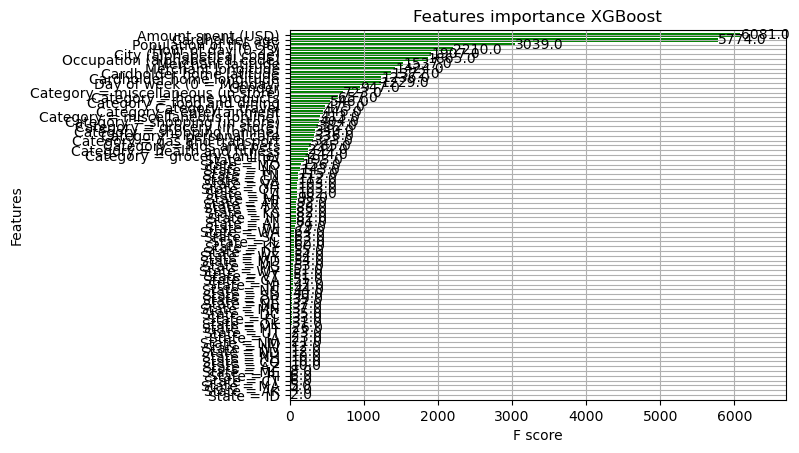

In [106]:
_, ax = plt.subplots(1, 1)
xgb.plot_importance(model, height=0.8, title=f"Features importance {model_name}", ax=ax, color="green") 
plt.show()

##### feature importance (Table 4)


In [107]:
# Decision 2 (Revision_Plan_V03.md): XGBoost replaces k-NN in the set of
# interpreted models -- k-NN is now the weakest model, XGBoost the strongest.
# Importance is total gain, normalised to sum to 1, so it is on the same scale as
# the impurity-based importances of the tree models in Table 4.
assert model_name == "XGBoost", model_name
_gain = model.get_score(importance_type='total_gain')
feature_imp = pd.DataFrame({'Feature': predictors,
                            'Feature importance': [_gain.get(f, 0.0) for f in predictors]})
feature_imp['Feature importance'] = feature_imp['Feature importance'] / feature_imp['Feature importance'].sum()
feature_df[model_name] = feature_imp['Feature importance']

feature_imp.sort_values('Feature importance', ascending=False)


,Feature,Feature importance
0,Amount spent (USD),0.612908
8,Hour of day (0-23),0.087751
12,Category = gas and transport,0.065165
7,Cardholder age,0.044818
14,Category = grocery (in store),0.030650
...,...,...
30,State = CT,0.000017
57,State = NV,0.000016
43,State = MA,0.000005
37,State = ID,0.000003


##### SHAP


(2000, 77)
SHAP beeswarm, both Non fraud and fraud, XGBoost:



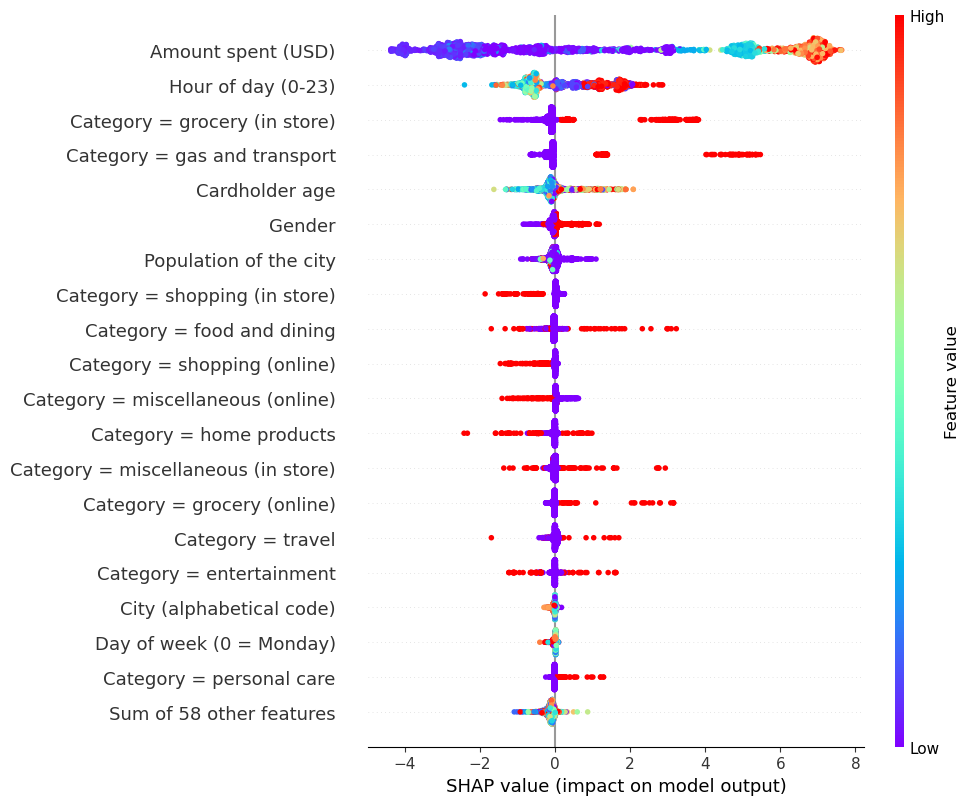

In [108]:
# SHAP beeswarm for random samples (same balanced 2x1000 sample as the other models)
explainer = shap.TreeExplainer(model)
X = df_random[predictors]

shap_values = explainer(X)

print(shap_values.shape)
print(f"SHAP beeswarm, both Non fraud and fraud, {model_name}:\n")

shap.plots.beeswarm(shap_values, max_display=20, color=plt.get_cmap("rainbow"))


In [109]:
# SHAP force graph

shap.initjs()
shap.plots.force(shap_values, feature_names=predictors)


##### LIME


In [110]:
print(f"LIME, {model_name}:")

start = datetime.now()
print("start:", start)

warnings.filterwarnings('ignore') # disable Python warning for this cell

# V25: seeded -- without random_state LIME draws different perturbation samples each
# run, so the averaged contributions changed between otherwise identical runs
# (by up to 0.0045; the top-ranked conditions were stable).
explainer = lime.lime_tabular.LimeTabularExplainer(train_df[predictors].values,
random_state=RANDOM_STATE,
feature_names=predictors,
class_names=['class_0', 'class_1'],
discretize_continuous=True)

print("Baseline probability:", valid_df[target].values.mean()) # obtain baseline probability

n = 500
contributions_list = []
for i in range(n):
    exp = explainer.explain_instance(df_random[predictors].iloc[i], XGBoostWrapper(model).predict_proba, num_features=len(predictors), num_samples=2000)
    contributions = exp.as_list()  # [(feature1, value1), (feature2, value2), ...]
    contributions_list.extend(contributions)

contributions_dict = {}
for feature, value in contributions_list:
    if feature not in contributions_dict:
        contributions_dict[feature] = []
    contributions_dict[feature].append(value)

for k, v in contributions_dict.items():
    average = np.mean(v)
    contributions_dict[k] = average

df_lime = pd.DataFrame.from_dict(contributions_dict, orient='index')

df_lime.to_csv(f"result_csv/LIME_{model_name}_{TAG}.csv")

end = datetime.now()
print("end:", end)
print("time required:", end-start)

df_lime

LIME, XGBoost:
start: 2026-10-13 14:19:23.209185


Baseline probability: 0.005644162316661124


end: 2026-10-13 14:20:33.125083
time required: 0:01:09.915898


,0
Category = gas and transport <= 0.00,-0.239022
Category = grocery (in store) <= 0.00,-0.135699
State = CT <= 0.00,-0.003132
47.40 < Amount spent (USD) <= 83.06,-0.079884
State = AZ > 0.00,0.068845
...,...
State = SD > 0.00,0.018188
State = VT > 0.00,0.017934
State = NH > 0.00,0.032837
State = CT > 0.00,0.078963


##### get optimal threshold

Threshold of 0.0:


Predicted,1
Actual,
0,206300
1,1171


F1 Score of XGBoost =  0.011224969085802476


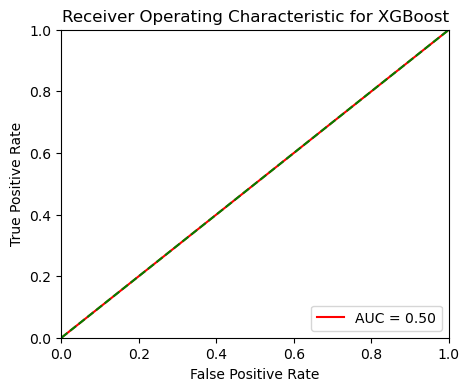




Threshold of 0.025:


Predicted,0,1
Actual,,
0,202013,4287
1,17,1154


F1 Score of XGBoost =  0.3490623109497883


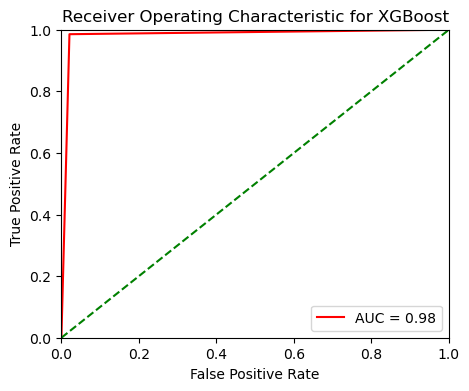




Threshold of 0.05:


Predicted,0,1
Actual,,
0,203699,2601
1,29,1142


F1 Score of XGBoost =  0.4647944647944648


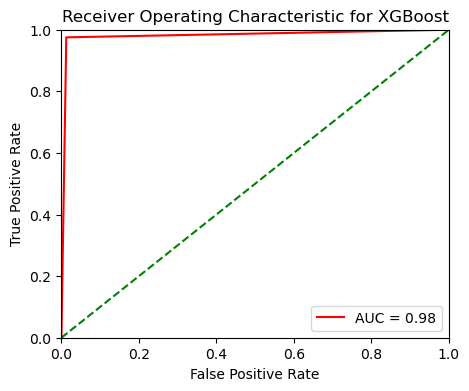




Threshold of 0.07500000000000001:


Predicted,0,1
Actual,,
0,204381,1919
1,42,1129


F1 Score of XGBoost =  0.5351979141976771


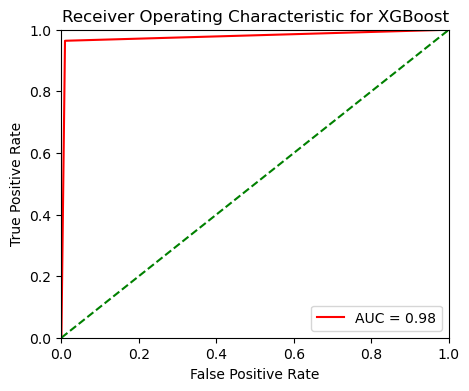




Threshold of 0.1:


Predicted,0,1
Actual,,
0,204742,1558
1,54,1117


F1 Score of XGBoost =  0.5808632345293812


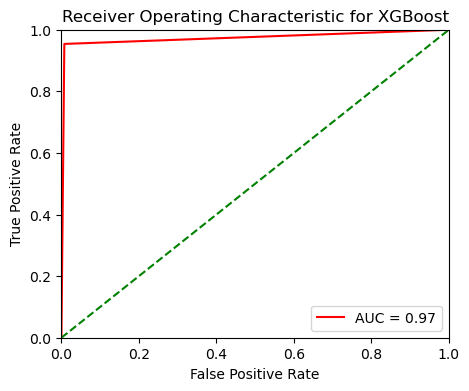




Threshold of 0.125:


Predicted,0,1
Actual,,
0,204993,1307
1,61,1110


F1 Score of XGBoost =  0.6187290969899666


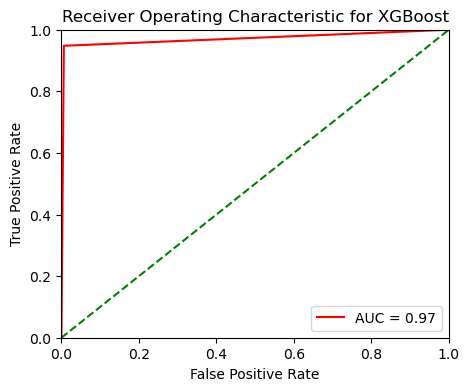




Threshold of 0.15000000000000002:


Predicted,0,1
Actual,,
0,205163,1137
1,65,1106


F1 Score of XGBoost =  0.6479203280609256


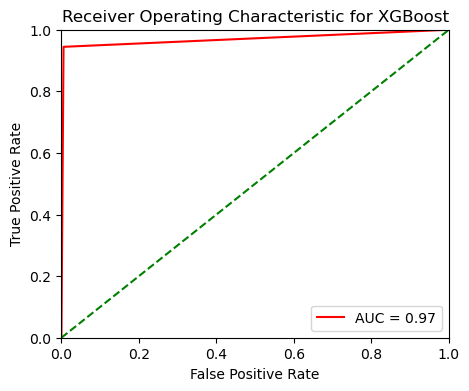




Threshold of 0.17500000000000002:


Predicted,0,1
Actual,,
0,205315,985
1,77,1094


F1 Score of XGBoost =  0.6732307692307692


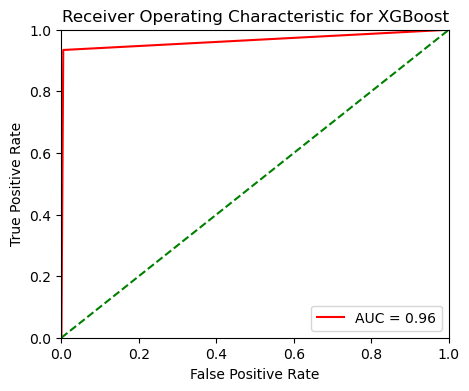




Threshold of 0.2:


Predicted,0,1
Actual,,
0,205431,869
1,85,1086


F1 Score of XGBoost =  0.6948176583493282


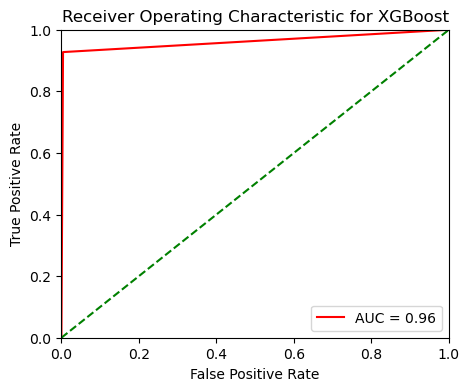




Threshold of 0.225:


Predicted,0,1
Actual,,
0,205536,764
1,93,1078


F1 Score of XGBoost =  0.7155658811815466


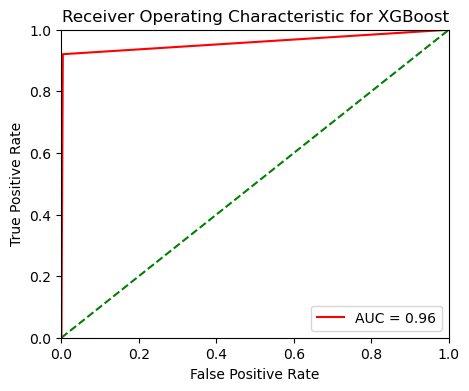




Threshold of 0.25:


Predicted,0,1
Actual,,
0,205623,677
1,97,1074


F1 Score of XGBoost =  0.7351129363449692


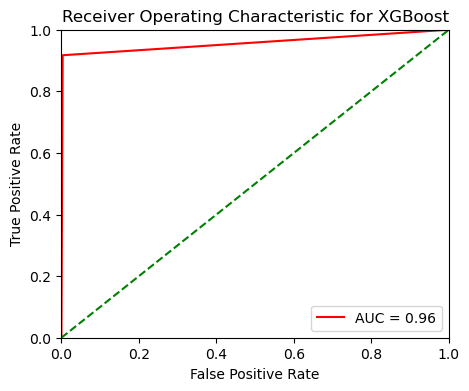




Threshold of 0.275:


Predicted,0,1
Actual,,
0,205695,605
1,103,1068


F1 Score of XGBoost =  0.7510548523206751


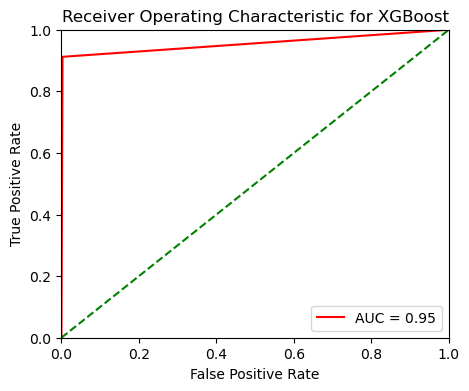




Threshold of 0.30000000000000004:


Predicted,0,1
Actual,,
0,205757,543
1,110,1061


F1 Score of XGBoost =  0.7646846846846846


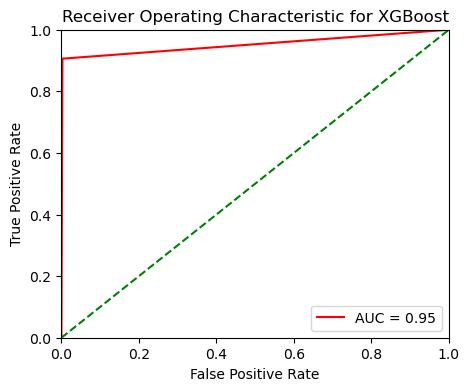




Threshold of 0.325:


Predicted,0,1
Actual,,
0,205800,500
1,116,1055


F1 Score of XGBoost =  0.7740278796771827


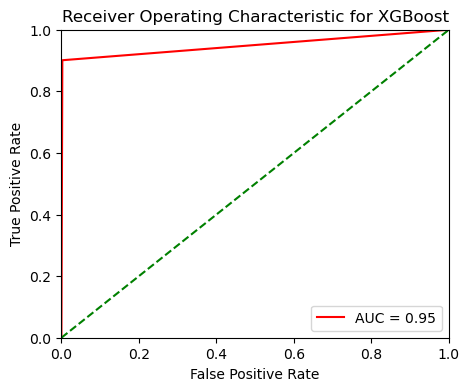




Threshold of 0.35000000000000003:


Predicted,0,1
Actual,,
0,205843,457
1,120,1051


F1 Score of XGBoost =  0.7846211272863008


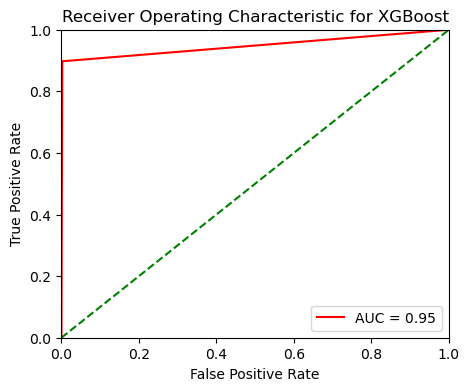




Threshold of 0.375:


Predicted,0,1
Actual,,
0,205879,421
1,128,1043


F1 Score of XGBoost =  0.791650853889943


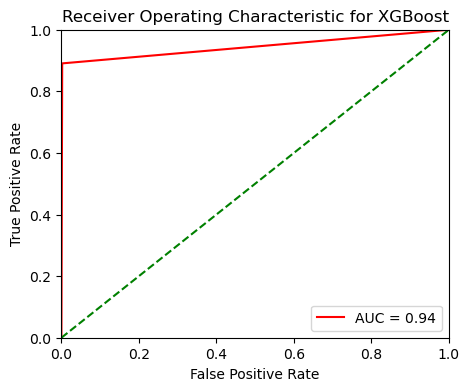




Threshold of 0.4:


Predicted,0,1
Actual,,
0,205913,387
1,133,1038


F1 Score of XGBoost =  0.7996918335901386


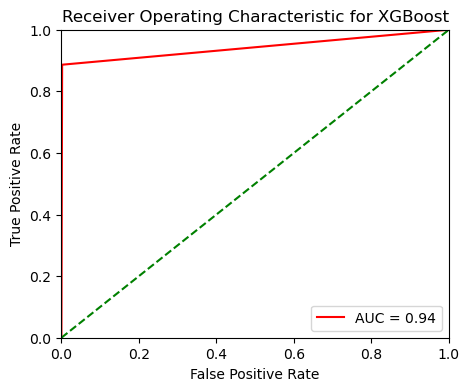




Threshold of 0.42500000000000004:


Predicted,0,1
Actual,,
0,205945,355
1,141,1030


F1 Score of XGBoost =  0.8059467918622848


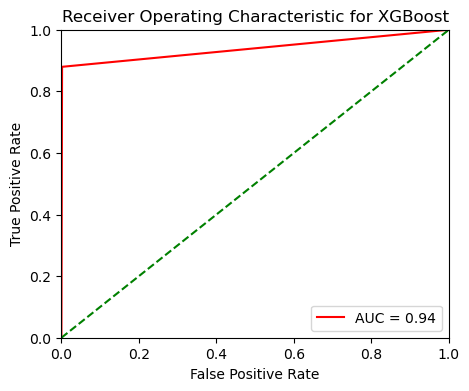




Threshold of 0.45:


Predicted,0,1
Actual,,
0,205974,326
1,144,1027


F1 Score of XGBoost =  0.8137876386687797


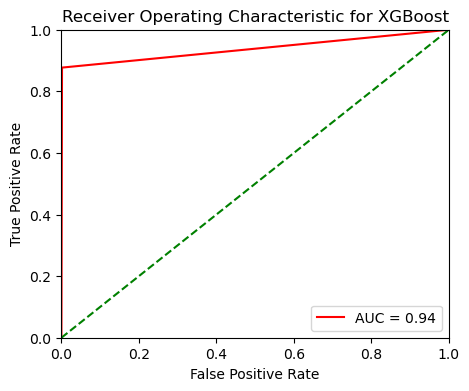




Threshold of 0.47500000000000003:


Predicted,0,1
Actual,,
0,205999,301
1,146,1025


F1 Score of XGBoost =  0.8209851822186623


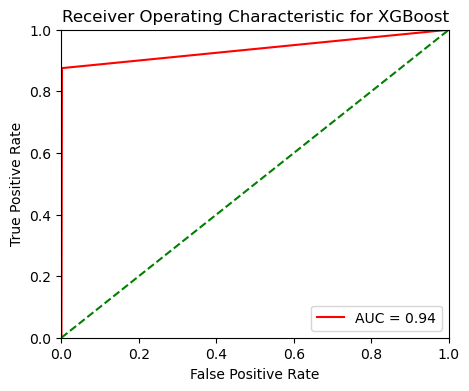




Threshold of 0.5:


Predicted,0,1
Actual,,
0,206020,280
1,148,1023


F1 Score of XGBoost =  0.8270008084074374


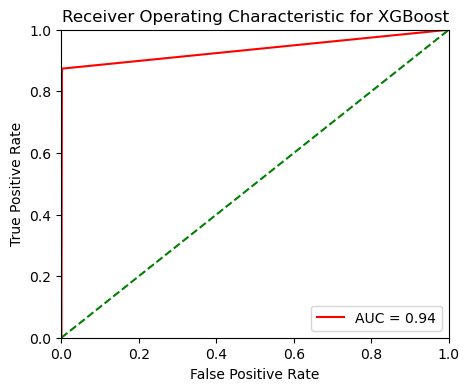




Threshold of 0.525:


Predicted,0,1
Actual,,
0,206055,245
1,154,1017


F1 Score of XGBoost =  0.8360049321824907


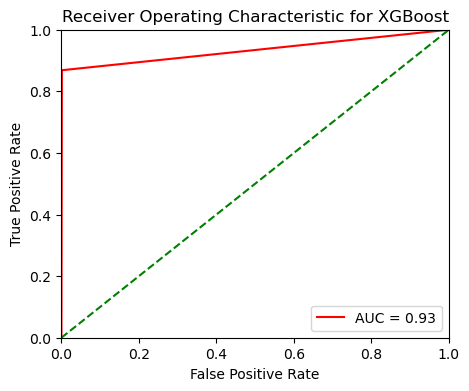




Threshold of 0.55:


Predicted,0,1
Actual,,
0,206085,215
1,156,1015


F1 Score of XGBoost =  0.8454810495626822


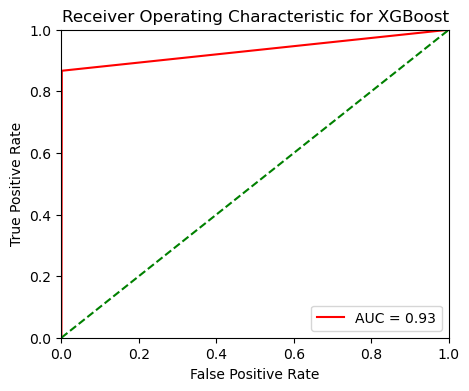




Threshold of 0.5750000000000001:


Predicted,0,1
Actual,,
0,206118,182
1,160,1011


F1 Score of XGBoost =  0.8553299492385786


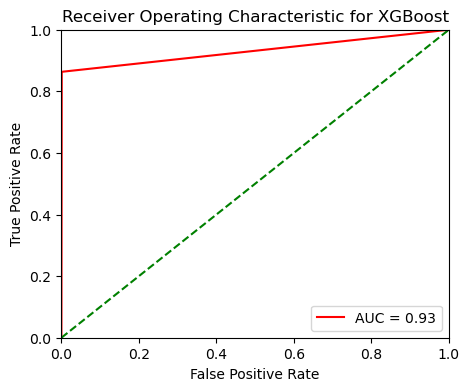

In [111]:
thshld_list = np.arange(0, 0.6, 0.025)

for th in thshld_list: # test best threshold value of turning probability into binary
    binary_preds = [1 if prob > th else 0 for prob in preds]
    print(f"Threshold of {th}:")
    cm = pd.crosstab(valid_df[target].values, binary_preds, rownames=['Actual'], colnames=['Predicted'])
    display(HTML(cm.to_html(index=True,header=True)))
    
    f1 = f1_score(valid_df[target].values, binary_preds)
    print(f"F1 Score of {model_name} = ", f1)
    
    fpr, tpr, threshold = metrics.roc_curve(valid_df[target].values, binary_preds)
    roc_auc = metrics.auc(fpr, tpr)
    plt.figure(figsize = (5,4))
    plt.title('Receiver Operating Characteristic for XGBoost')
    plt.plot(fpr, tpr, 'r', label = 'AUC = %0.2f' % roc_auc)
    plt.legend(loc = 'lower right')
    plt.plot([0, 1], [0, 1], 'g--')
    plt.xlim([0, 1])
    plt.ylim([0, 1])
    plt.ylabel('True Positive Rate')
    plt.xlabel('False Positive Rate')
    plt.show()

    print("\n\n")

In [112]:
binary_preds = [1 if prob > 0.5 else 0 for prob in preds] # 0.5 for comparability with the other models; a stated threshold rule is Phase 2 (A4)

##### confusion matrix

In [113]:
cm = pd.crosstab(valid_df[target].values, binary_preds, rownames=['Actual'], colnames=['Predicted'])

# print(valid_df[target].values)
# print(binary_preds)

display(HTML(cm.to_html(index=True,header=True)))

fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True,ax=ax1,
            linewidths=.2,linecolor="Darkblue", cmap="Blues")

Predicted,0,1
Actual,,
0,206020,280
1,148,1023


<Axes: xlabel='Predicted', ylabel='Actual'>

##### score

In [114]:
recall = recall_score(valid_df[target].values, binary_preds, average='binary')
print(f"Recall Score of {model_name} = ", recall)

precision = precision_score(valid_df[target].values, binary_preds, average='binary')
print(f"Precision Score of {model_name} = ", precision)

specificity = recall_score(valid_df[target].values, binary_preds, pos_label=0)
print(f"Specificity Score of {model_name} = ", specificity)

f1 = f1_score(valid_df[target].values, binary_preds)
print(f"F1 Score of {model_name} = ", f1)

Recall Score of XGBoost =  0.8736122971818958
Precision Score of XGBoost =  0.7851112816577129
Specificity Score of XGBoost =  0.9986427532719341


F1 Score of XGBoost =  0.8270008084074374


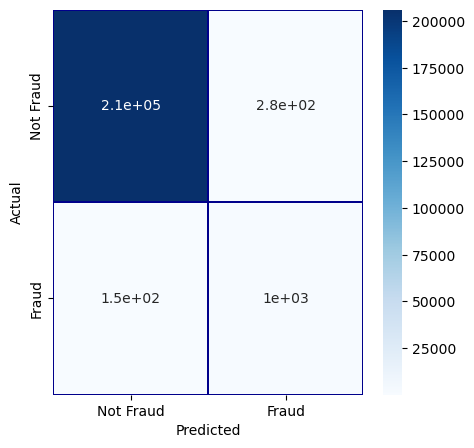

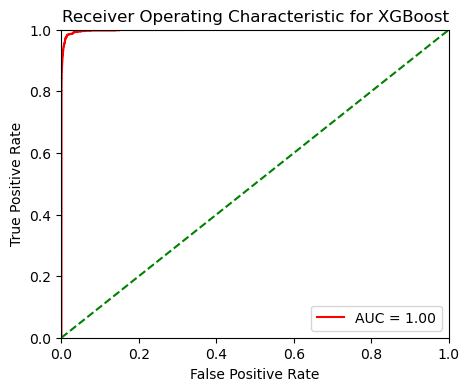

In [115]:
fpr, tpr, threshold = metrics.roc_curve(valid_df[target].values, preds) # use probability instead of binary
roc_auc = metrics.auc(fpr, tpr)

plt.figure(figsize = (5,4))
plt.title(f'Receiver Operating Characteristic for {model_name}')
plt.plot(fpr, tpr, 'r', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'g--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [116]:
roc_auc_score(valid_df[target].values, preds) # probability

np.float64(0.9983123228051642)

In [117]:
AUC = roc_auc_score(valid_df[target].values, preds)
AUCPR = average_precision_score(valid_df[target].values, preds)

print(f"AUC of {model_name} = ", AUC)
print(f"AUC-PR of {model_name} = ", AUCPR)

AUC, AUCPR


AUC of XGBoost =  0.9983123228051642
AUC-PR of XGBoost =  0.9233918932055917


(np.float64(0.9983123228051642), np.float64(0.9233918932055917))

In [118]:
# D9: operating point at the ALERT_RATE investigation budget
score_at_budget(model_name, valid_df[target].values, preds)

budget_df


XGBoost: threshold 0.7351, alert rate 0.50%, recall 0.8190, precision 0.9248


,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,CatBoost,XGBoost
0,Operating threshold,0.064098,0.500000,0.346805,0.599031,0.384302,0.735120
1,Alert rate,0.004998,0.005013,0.004998,0.005172,0.004998,0.004998
2,Recall (budget),0.384287,0.821520,0.827498,0.512383,0.819812,0.818958
3,Precision (budget),0.433944,0.925000,0.934426,0.559180,0.925747,0.924783
4,F1 (budget),0.407609,0.870194,0.877717,0.534759,0.869565,0.868659
5,MCC (budget),0.405206,0.871048,0.878703,0.532748,0.870492,0.869579


In [119]:
# V24: register XGBoost for the one-time test evaluation
assert model_name == "XGBoost", model_name
fitted_models[model_name] = lambda d, m=model: m.predict(xgb.DMatrix(d[predictors]))
valid_thresholds[model_name] = budget_threshold(preds)


In [120]:
MCC = matthews_corrcoef(valid_df[target].values, binary_preds)
print(f"Matthew's Correlation Coefficient of {model_name} = ", MCC)

bcr = (recall+specificity)/2
print(f"Balanced Classification Rate of {model_name} = ", bcr)

Matthew's Correlation Coefficient of XGBoost =  0.827158462793158
Balanced Classification Rate of XGBoost =  0.936127525226915


In [121]:
result_df[model_name] = [recall, precision, specificity, f1, AUC, AUCPR, MCC, bcr]

result_df

,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,CatBoost,XGBoost
0,Recall,0.006832,0.810418,0.801025,0.942784,0.791631,0.873612
1,Precision,0.087912,0.929481,0.957143,0.100794,0.948823,0.785111
2,Specificity,0.999598,0.999651,0.999796,0.952259,0.999758,0.998643
3,F1 Score,0.012678,0.865876,0.872152,0.182118,0.863128,0.827001
4,AUC,0.808536,0.983273,0.997088,0.986544,0.997600,0.998312
5,AUC-PR,0.217889,0.894839,0.922917,0.558292,0.925465,0.923392
6,MCC,0.023004,0.867221,0.874984,0.299850,0.865998,0.827158
7,Balanced Classification Rate,0.503215,0.905035,0.900411,0.947521,0.895694,0.936128


#### LightGBM

In [122]:
# D8: hyperparameters from the TUNED table (after the predictor list).
params = {'boosting_type': 'gbdt', 'objective': 'binary', 'metric': 'average_precision',
          'bagging_freq': 1, 'nthread': 8, 'verbose': -1, 'seed': RANDOM_STATE,
          **PARAMS["LightGBM"]}

model_name = "LightGBM"


In [123]:
# LightGBM rejects ':' and '*' in feature names, and the human-readable column
# names set earlier contain both (e.g. "Interaction 1: Non-essential vs.
# essential*Average item cost"). Passing them raises
#   [LightGBM] [Fatal] Do not support special JSON characters in feature name.
# In V22 that killed the cell, left `preds` holding the previous model's
# predictions, and the scoring cells below silently rescored XGBoost under
# LightGBM's name. Use positional names and keep the mapping for the plots.
lgb_feature_names = [f"f{i}" for i in range(len(predictors))]
lgb_feature_map = dict(zip(lgb_feature_names, predictors))

dtrain = lgb.Dataset(train_df[predictors].values,
                     label=train_df[target].values,
                     feature_name=lgb_feature_names)

dvalid = lgb.Dataset(valid_df[predictors].values,
                     label=valid_df[target].values,
                     feature_name=lgb_feature_names)


In [124]:
evals_results = {}

model = lgb.train(params, 
                  dtrain, 
                  valid_sets=[dtrain, dvalid], 
                  valid_names=['train','valid'], 
                  # evals_result=evals_results, 
                  num_boost_round=MAX_ROUNDS,
                  # early_stopping_rounds=2*EARLY_STOP,
                  callbacks=[lgb.early_stopping(stopping_rounds=2*EARLY_STOP),],
                  # verbose_eval=VERBOSE_EVAL, 
                  feval=None)

Training until validation scores don't improve for 100 rounds


Early stopping, best iteration is:
[110]	train's average_precision: 0.97282	valid's average_precision: 0.917612


In [125]:
class LightGBMWrapper:
    def __init__(self, model):
        self.model = model

    def predict_proba(self, data):
        # Check if best_iteration exists, otherwise use the default
        if hasattr(self.model, 'best_iteration'):
            predictions = self.model.predict(data, num_iteration=self.model.best_iteration)
        else:
            predictions = self.model.predict(data)

        # Ensure that the prediction output is 2D (num_samples, num_classes)
        # If the predictions are for a binary classification problem
        if len(predictions.shape) == 1:
            predictions = np.vstack((1 - predictions, predictions)).T

        return predictions

In [126]:
preds = model.predict(valid_df[predictors].values)

binary_preds = [1 if prob > 0.5 else 0 for prob in preds]

##### feature importance

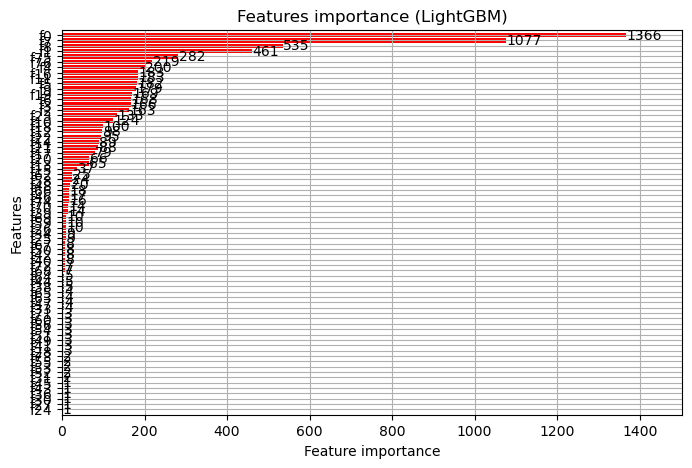

In [127]:
fig, (ax) = plt.subplots(ncols=1, figsize=(8,5))
lgb.plot_importance(model, height=0.8, title="Features importance (LightGBM)", ax=ax,color="red") 
plt.show()

##### confusion matrix

In [128]:
cm = pd.crosstab(valid_df[target].values, binary_preds, rownames=['Actual'], colnames=['Predicted'])

# print(valid_df[target].values)
# print(binary_preds)

display(HTML(cm.to_html(index=True,header=True)))

fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True,ax=ax1,
            linewidths=.2,linecolor="Darkblue", cmap="Blues")

Predicted,0,1
Actual,,
0,206230,70
1,222,949


<Axes: xlabel='Predicted', ylabel='Actual'>

##### score

In [129]:
recall = recall_score(valid_df[target].values, binary_preds, average='binary')
print(f"Recall Score of {model_name} = ", recall)

precision = precision_score(valid_df[target].values, binary_preds, average='binary')
print(f"Precision Score of {model_name} = ", precision)

specificity = recall_score(valid_df[target].values, binary_preds, pos_label=0)
print(f"Specificity Score of {model_name} = ", specificity)

f1 = f1_score(valid_df[target].values, binary_preds)
print(f"F1 Score of {model_name} = ", f1)

Recall Score of LightGBM =  0.8104184457728437
Precision Score of LightGBM =  0.9313052011776252
Specificity Score of LightGBM =  0.9996606883179835


F1 Score of LightGBM =  0.8666666666666667


In [130]:
roc_auc_score(valid_df[target].values, preds) # probability, not binary

np.float64(0.9977662305191755)

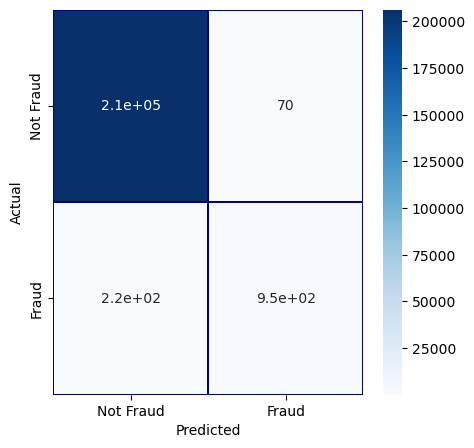

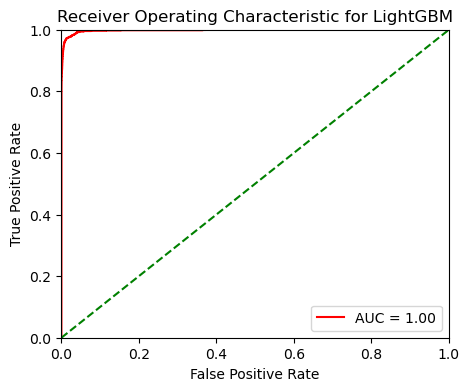

In [131]:
fpr, tpr, threshold = metrics.roc_curve(valid_df[target].values, preds) # use probability instead of binary
roc_auc = metrics.auc(fpr, tpr)

plt.figure(figsize = (5,4))
plt.title(f'Receiver Operating Characteristic for {model_name}')
plt.plot(fpr, tpr, 'r', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'g--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [132]:
AUC = roc_auc_score(valid_df[target].values, preds)
AUCPR = average_precision_score(valid_df[target].values, preds)

print(f"AUC of {model_name} = ", AUC)
print(f"AUC-PR of {model_name} = ", AUCPR)

AUC, AUCPR


AUC of LightGBM =  0.9977662305191755
AUC-PR of LightGBM =  0.9176119112775191


(np.float64(0.9977662305191755), np.float64(0.9176119112775191))

In [133]:
# D9: operating point at the ALERT_RATE investigation budget
score_at_budget(model_name, valid_df[target].values, preds)

budget_df


LightGBM: threshold 0.4191, alert rate 0.50%, recall 0.8190, precision 0.9248


,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,CatBoost,XGBoost,LightGBM
0,Operating threshold,0.064098,0.500000,0.346805,0.599031,0.384302,0.735120,0.419057
1,Alert rate,0.004998,0.005013,0.004998,0.005172,0.004998,0.004998,0.004998
2,Recall (budget),0.384287,0.821520,0.827498,0.512383,0.819812,0.818958,0.818958
3,Precision (budget),0.433944,0.925000,0.934426,0.559180,0.925747,0.924783,0.924783
4,F1 (budget),0.407609,0.870194,0.877717,0.534759,0.869565,0.868659,0.868659
5,MCC (budget),0.405206,0.871048,0.878703,0.532748,0.870492,0.869579,0.869579


In [134]:
# V24: register LightGBM for the one-time test evaluation
assert model_name == "LightGBM", model_name
fitted_models[model_name] = lambda d, m=model: m.predict(d[predictors].values)
valid_thresholds[model_name] = budget_threshold(preds)


In [135]:
MCC = matthews_corrcoef(valid_df[target].values, binary_preds)
print(f"Matthew's Correlation Coefficient of {model_name} = ", MCC)

bcr = (recall+specificity)/2
print(f"Balanced Classification Rate of {model_name} = ", bcr)

Matthew's Correlation Coefficient of LightGBM =  0.8680782363120645
Balanced Classification Rate of LightGBM =  0.9050395670454137


In [136]:
result_df[model_name] = [recall, precision, specificity, f1, AUC, AUCPR, MCC, bcr]

result_df

,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,CatBoost,XGBoost,LightGBM
0,Recall,0.006832,0.810418,0.801025,0.942784,0.791631,0.873612,0.810418
1,Precision,0.087912,0.929481,0.957143,0.100794,0.948823,0.785111,0.931305
2,Specificity,0.999598,0.999651,0.999796,0.952259,0.999758,0.998643,0.999661
3,F1 Score,0.012678,0.865876,0.872152,0.182118,0.863128,0.827001,0.866667
4,AUC,0.808536,0.983273,0.997088,0.986544,0.997600,0.998312,0.997766
5,AUC-PR,0.217889,0.894839,0.922917,0.558292,0.925465,0.923392,0.917612
6,MCC,0.023004,0.867221,0.874984,0.299850,0.865998,0.827158,0.868078
7,Balanced Classification Rate,0.503215,0.905035,0.900411,0.947521,0.895694,0.936128,0.905040


#### K-NN

In [137]:
# D8: hyperparameters from the TUNED table (after the predictor list).
# k=1 was both the worst model and the one most inflated by the random split.
clf = KNeighborsClassifier(**PARAMS["K-NN"], n_jobs=-1)

model_name = "K-NN"


In [138]:
clf.fit(train_df[predictors], train_df[target].values)

KNeighborsClassifier(n_jobs=-1, n_neighbors=50, weights='distance')

In [139]:
preds = clf.predict_proba(valid_df[predictors])[:, 1]

binary_preds = [1 if prob > 0.5 else 0 for prob in preds]

##### LIME

*LIME is no longer run for k-NN.* Decision 2 in `Revision_Plan_V03.md`: k-NN is the weakest of the eight models (validation AUC-PR 0.150), so it was replaced by XGBoost in the set of interpreted models. k-NN stays in the performance comparison as a negative result.


##### confusion matrix

In [140]:
cm = pd.crosstab(valid_df[target].values, binary_preds, rownames=['Actual'], colnames=['Predicted'])
display(HTML(cm.to_html(index=True,header=True)))

fig, (ax1) = plt.subplots(ncols=1, figsize=(5,5))
sns.heatmap(cm, 
            xticklabels=['Not Fraud', 'Fraud'],
            yticklabels=['Not Fraud', 'Fraud'],
            annot=True,ax=ax1,
            linewidths=.2,linecolor="Darkblue", cmap="Blues")

Predicted,0,1
Actual,,
0,206157,143
1,1043,128


<Axes: xlabel='Predicted', ylabel='Actual'>

##### score

In [141]:
recall = recall_score(valid_df[target].values, binary_preds, average='binary')
print(f"Recall Score of {model_name} = ", recall)

precision = precision_score(valid_df[target].values, binary_preds, average='binary')
print(f"Precision Score of {model_name} = ", precision)

specificity = recall_score(valid_df[target].values, binary_preds, pos_label=0)
print(f"Specificity Score of {model_name} = ", specificity)

f1 = f1_score(valid_df[target].values, binary_preds)
print(f"F1 Score of {model_name} = ", f1)

Recall Score of K-NN =  0.10930828351836037
Precision Score of K-NN =  0.47232472324723246
Specificity Score of K-NN =  0.9993068347067378


F1 Score of K-NN =  0.17753120665742025


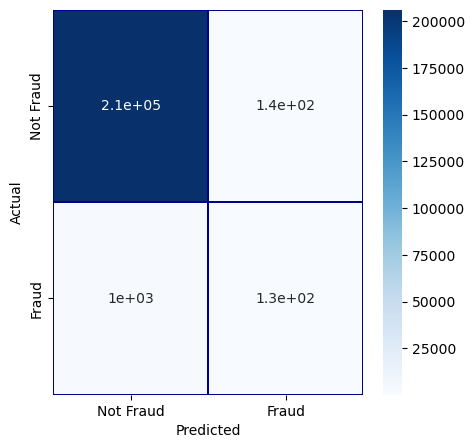

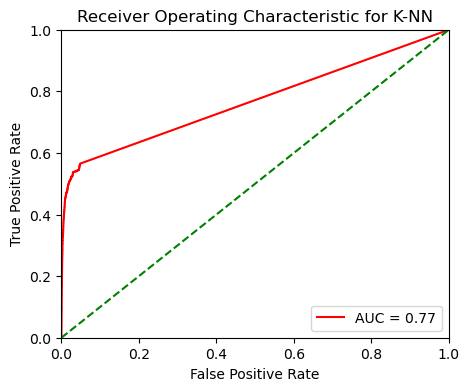

In [142]:
fpr, tpr, threshold = metrics.roc_curve(valid_df[target].values, preds)
roc_auc = metrics.auc(fpr, tpr)

plt.figure(figsize = (5,4))
plt.title(f'Receiver Operating Characteristic for {model_name}')
plt.plot(fpr, tpr, 'r', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1],'g--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

In [143]:
AUC = roc_auc_score(valid_df[target].values, preds)
AUCPR = average_precision_score(valid_df[target].values, preds)

print(f"AUC of {model_name} = ", AUC)
print(f"AUC-PR of {model_name} = ", AUCPR)

AUC, AUCPR


AUC of K-NN =  0.7680139752369117
AUC-PR of K-NN =  0.19636013589001794


(np.float64(0.7680139752369117), np.float64(0.19636013589001794))

In [144]:
# D9: operating point at the ALERT_RATE investigation budget
score_at_budget(model_name, valid_df[target].values, preds)

budget_df


K-NN: threshold 0.1988, alert rate 0.50%, recall 0.3160, precision 0.3568


,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,CatBoost,XGBoost,LightGBM,K-NN
0,Operating threshold,0.064098,0.500000,0.346805,0.599031,0.384302,0.735120,0.419057,0.198774
1,Alert rate,0.004998,0.005013,0.004998,0.005172,0.004998,0.004998,0.004998,0.004998
2,Recall (budget),0.384287,0.821520,0.827498,0.512383,0.819812,0.818958,0.818958,0.315969
3,Precision (budget),0.433944,0.925000,0.934426,0.559180,0.925747,0.924783,0.924783,0.356798
4,F1 (budget),0.407609,0.870194,0.877717,0.534759,0.869565,0.868659,0.868659,0.335145
5,MCC (budget),0.405206,0.871048,0.878703,0.532748,0.870492,0.869579,0.869579,0.332220


In [145]:
# V24: register K-NN for the one-time test evaluation
assert model_name == "K-NN", model_name
fitted_models[model_name] = lambda d, m=clf: m.predict_proba(d[predictors])[:, 1]
valid_thresholds[model_name] = budget_threshold(preds)


In [146]:
# Phase 1: this cell used to overwrite AUC with
# roc_auc_score(valid_df[target].values, binary_preds), which for hard labels
# returns (recall + specificity) / 2 rather than an ROC-AUC. Removed.
AUC, AUCPR


(np.float64(0.7680139752369117), np.float64(0.19636013589001794))

In [147]:
MCC = matthews_corrcoef(valid_df[target].values, binary_preds)
print(f"Matthew's Correlation Coefficient of {model_name} = ", MCC)

bcr = (recall+specificity)/2
print(f"Balanced Classification Rate of {model_name} = ", bcr)

Matthew's Correlation Coefficient of K-NN =  0.22528839436451148
Balanced Classification Rate of K-NN =  0.554307559112549


#### Result of All Models

In [148]:
result_df[model_name] = [recall, precision, specificity, f1, AUC, AUCPR, MCC, bcr]

result_df

,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,CatBoost,XGBoost,LightGBM,K-NN
0,Recall,0.006832,0.810418,0.801025,0.942784,0.791631,0.873612,0.810418,0.109308
1,Precision,0.087912,0.929481,0.957143,0.100794,0.948823,0.785111,0.931305,0.472325
2,Specificity,0.999598,0.999651,0.999796,0.952259,0.999758,0.998643,0.999661,0.999307
3,F1 Score,0.012678,0.865876,0.872152,0.182118,0.863128,0.827001,0.866667,0.177531
4,AUC,0.808536,0.983273,0.997088,0.986544,0.997600,0.998312,0.997766,0.768014
5,AUC-PR,0.217889,0.894839,0.922917,0.558292,0.925465,0.923392,0.917612,0.196360
6,MCC,0.023004,0.867221,0.874984,0.299850,0.865998,0.827158,0.868078,0.225288
7,Balanced Classification Rate,0.503215,0.905035,0.900411,0.947521,0.895694,0.936128,0.905040,0.554308


In [149]:
# Phase 1 (Revision_Plan_V01.md, item 5): persist the corrected metrics table.
# V04 was saved by hand; V05 is written here so the re-run is reproducible and
# can be diffed against the submitted numbers.
#
# What changed from models_metric_result_V04.csv:
#   - AUC now comes from predicted probabilities for every model. In V04 six of
#     the eight models passed thresholded 0/1 labels to roc_auc_score, which
#     returns (recall + specificity) / 2, so the AUC column duplicated the
#     Balanced Classification Rate column.
#   - AUC-PR (average precision) added, the metric Reviewer 1 asked for.
#   - XGBoost and LightGBM are scored on valid_df like the other six; in V04
#     they were scored on test_df, and XGBoost additionally at a 0.175
#     threshold rather than 0.5.
#   - "LightGDM" is spelled LightGBM.
# D6/D9: V06 carries the chronological split and the budget operating point.
result_df.to_csv(f"result_csv/models_metric_result_V06_{TAG}.csv", index=False)
budget_df.to_csv(f"result_csv/operating_point_V01_{TAG}.csv", index=False)

result_df


# Guard against the failure mode that corrupted the first V23 run: if a model's
# cell raises, `preds` keeps the previous model's predictions and the scoring
# cells below rescore it under the new name, silently. Two identical columns is
# the signature. LightGBM's Dataset cell failed this way and duplicated XGBoost.
_num = result_df.set_index(result_df.columns[0]).astype(float)
for _a in range(len(_num.columns)):
    for _b in range(_a + 1, len(_num.columns)):
        _ca, _cb = _num.columns[_a], _num.columns[_b]
        assert not _num[_ca].equals(_num[_cb]), (
            f"{_ca} and {_cb} have identical metrics -- one of their cells "
            f"almost certainly failed and reused the other's predictions")
print("column-duplication check passed")


column-duplication check passed


In [150]:
# ===========================================================================
# V24: the one-time evaluation on the held-out TEST set. These are the numbers
# to report in the paper.
#
# Everything above is scored on valid_df, which by now has been used to choose
# the resampling setting (D7), the hyperparameters (D8), the early-stopping
# round for XGBoost and LightGBM, and the operating threshold (D9). Numbers from
# it are optimistic. test_df -- the chronologically last 20% of transactions --
# has influenced none of those choices and is scored exactly once here, with
# everything frozen: the models as fitted above, and each model's threshold as
# set on the validation set. The achieved alert rate on test will therefore
# drift from ALERT_RATE; that drift is part of the result, not an error.
# ===========================================================================
assert list(fitted_models) == [c for c in result_df.columns[1:]], list(fitted_models)

y_test = test_df[target].values
test_rows, test_budget_rows = {}, {}
for name, predict in fitted_models.items():
    proba = np.asarray(predict(test_df), dtype=float)
    binary = (proba > 0.5).astype(int)
    rec = recall_score(y_test, binary)
    spec = recall_score(y_test, binary, pos_label=0)
    test_rows[name] = [rec, precision_score(y_test, binary, zero_division=0), spec,
                       f1_score(y_test, binary), roc_auc_score(y_test, proba),
                       average_precision_score(y_test, proba),
                       matthews_corrcoef(y_test, binary), (rec + spec) / 2]
    thr, _, usable = valid_thresholds[name]
    if usable:
        alerted = (proba >= thr).astype(int)
        test_budget_rows[name] = [thr, alerted.mean(), recall_score(y_test, alerted),
                                  precision_score(y_test, alerted, zero_division=0),
                                  f1_score(y_test, alerted),
                                  matthews_corrcoef(y_test, alerted)]
    else:
        test_budget_rows[name] = [np.nan] * 6

test_result_df = pd.DataFrame({'metric\\model': list(result_df.iloc[:, 0]), **test_rows})
test_budget_df = pd.DataFrame({'metric\\model': [
    'Operating threshold (from validation)', 'Alert rate on test', 'Recall (budget)',
    'Precision (budget)', 'F1 (budget)', 'MCC (budget)'], **test_budget_rows})

# same guard as the validation export: identical columns mean a model's cell
# failed and its predictions were silently reused
_num = test_result_df.set_index(test_result_df.columns[0]).astype(float)
for _a in range(len(_num.columns)):
    for _b in range(_a + 1, len(_num.columns)):
        assert not _num.iloc[:, _a].equals(_num.iloc[:, _b]), (_num.columns[_a], _num.columns[_b])

test_result_df.to_csv(f"result_csv/test_metric_result_V01_{TAG}.csv", index=False)
test_budget_df.to_csv(f"result_csv/test_operating_point_V01_{TAG}.csv", index=False)
print(f"test set: {len(test_df)} transactions, {int(y_test.sum())} fraudulent")
test_result_df


test set: 259284 transactions, 1538 fraudulent


,metric\model,Logistic Regression,Decision Tree,Random Forest,AdaBoost,CatBoost,XGBoost,LightGBM,K-NN
0,Recall,0.011053,0.799090,0.795839,0.936931,0.806242,0.869311,0.811443,0.109233
1,Precision,0.149123,0.903676,0.951049,0.106276,0.938683,0.794887,0.921713,0.518519
2,Specificity,0.999624,0.999492,0.999756,0.952985,0.999686,0.998661,0.999589,0.999395
3,F1 Score,0.020581,0.848171,0.866549,0.190899,0.867436,0.830435,0.863071,0.180451
4,AUC,0.821965,0.985466,0.997431,0.985608,0.998162,0.998359,0.998270,0.771729
5,AUC-PR,0.241593,0.890076,0.919729,0.558009,0.923286,0.919963,0.919053,0.217790
6,MCC,0.039109,0.848942,0.869299,0.306962,0.869241,0.830218,0.864076,0.236116
7,Balanced Classification Rate,0.505338,0.899291,0.897797,0.944958,0.902964,0.933986,0.905516,0.554314


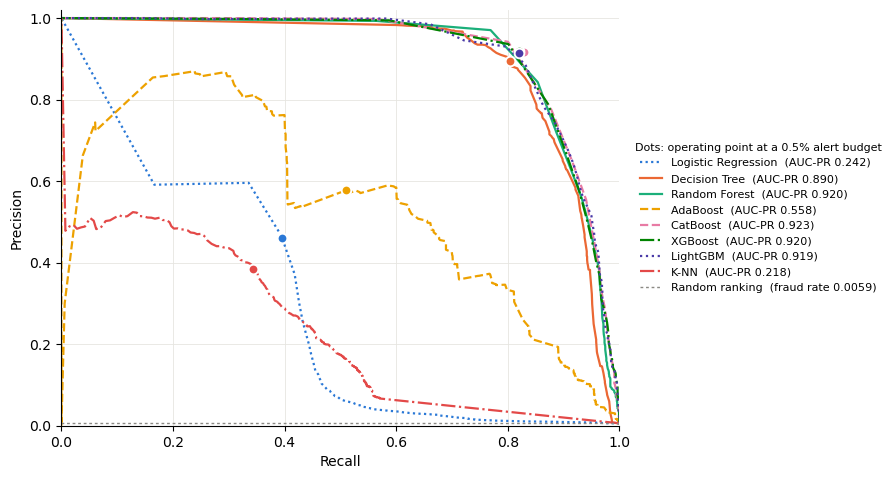

In [151]:
# V25 (Revision_Plan_V03.md, D9): precision-recall curves on the test set, with each
# model's operating point at the 0.5% alert budget marked. The curve points are also
# saved, so the base and client-feature runs can be drawn side by side afterwards.
# Colours: the dataviz reference palette in fixed model order (validated; colour
# follows the model, never its rank). Line style is a secondary cue so identity
# never rests on colour alone (colour-blind readers, greyscale print).
from sklearn.metrics import precision_recall_curve
os.makedirs("result_csv/figures", exist_ok=True)
PR_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
PR_STYLES = [(0, (1, 1.5)), "-", "-", "--", "--", "-.", ":", "-."]

pr_rows = []
fig, ax = plt.subplots(figsize=(7.2, 5.4))
for (name, predict), colour, style in zip(fitted_models.items(), PR_COLOURS, PR_STYLES):
    proba = np.asarray(predict(test_df), dtype=float)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    keep = np.unique(np.linspace(0, len(rec) - 1, 600).astype(int))   # thin for plotting and storage
    ax.plot(rec[keep], prec[keep], color=colour, ls=style, lw=1.6,
            label=f"{name}  (AUC-PR {average_precision_score(y_test, proba):.3f})")
    pr_rows += [dict(model=name, recall=r, precision=p, point="curve") for r, p in zip(rec[keep], prec[keep])]
    thr, _, usable = valid_thresholds[name]
    if usable:
        alerted = (proba >= thr).astype(int)
        r0, p0 = recall_score(y_test, alerted), precision_score(y_test, alerted, zero_division=0)
        ax.plot(r0, p0, "o", ms=7, color=colour, mec="white", mew=1.4, zorder=5)
        pr_rows.append(dict(model=name, recall=r0, precision=p0, point="operating point (0.5% budget)"))
# the random-ranking baseline goes in the legend: a text label on the plot collides
# with the weak models' curves, which run along the bottom
ax.axhline(y_test.mean(), color="#8a8984", lw=1, ls=(0, (2, 2)),
           label=f"Random ranking  (fraud rate {y_test.mean():.4f})")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.grid(color="#e6e5e1", lw=0.6); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(fontsize=8, frameon=False, loc="center left", bbox_to_anchor=(1.01, 0.5),
          title="Dots: operating point at a 0.5% alert budget", title_fontsize=8)
fig.savefig(f"result_csv/figures/pr_curves_test_{TAG}.png", dpi=300, bbox_inches="tight")
pd.DataFrame(pr_rows).to_csv(f"result_csv/pr_curves_test_{TAG}.csv", index=False)
plt.show()


In [152]:
# V26 (Phase 7 plan §10, 4C): no cross-model average. The four columns are different quantities
# -- impurity reduction (decision tree, random forest), prediction-value change (CatBoost) and
# total gain (XGBoost), each normalised to sum to 1 within its model -- so their mean has no common
# meaning. The table reports them side by side, ordered by CatBoost for display only; the one
# consistently defined cross-model measure is the permutation importance in
# revision_scripts/explain_compare.py.
feature_df.sort_values('CatBoost', inplace=True, ignore_index=True, ascending=False)
feature_df.to_csv(f"result_csv/feature_rank_table_V06_{TAG}.csv", index=False)
feature_df


,feature\model,Decision Tree,Random Forest,CatBoost,XGBoost
0,Amount spent (USD),0.302582,0.430285,0.179837,0.612908
1,Category = gas and transport,0.097481,0.044511,0.110243,0.065165
2,Hour of day (0-23),0.184834,0.124698,0.105970,0.087751
3,Cardholder age,0.088209,0.097865,0.072049,0.044818
4,Category = grocery (in store),0.253782,0.128982,0.071195,0.030650
...,...,...,...,...,...
72,State = AK,0.000000,0.000024,0.000004,0.000018
73,State = GA,0.000000,0.000453,0.000000,0.000238
74,State = HI,0.000000,0.000010,0.000000,0.000000
75,State = OK,0.000000,0.000352,0.000000,0.000072


In [153]:
# Decision 2: XGBoost replaces k-NN in the merged LIME table.
df_lime_dt = pd.read_csv(f"result_csv/LIME_Decision Tree_{TAG}.csv")
df_lime_dt.columns = ['features', 'DT']
                  
df_lime_rf = pd.read_csv(f"result_csv/LIME_Random Forest_{TAG}.csv")
df_lime_rf.columns = ['features', 'RF']

df_lime_catboost = pd.read_csv(f"result_csv/LIME_CatBoost_{TAG}.csv")
df_lime_catboost.columns = ['features', 'Catboost']

df_lime_xgb = pd.read_csv(f"result_csv/LIME_XGBoost_{TAG}.csv")
df_lime_xgb.columns = ['features', 'XGBoost']

df_lime_dt['features'] = df_lime_dt['features'].astype(str)
df_lime_rf['features'] = df_lime_rf['features'].astype(str)
df_lime_catboost['features'] = df_lime_catboost['features'].astype(str)
df_lime_xgb['features'] = df_lime_xgb['features'].astype(str)

df_lime_dt.sort_values('features', inplace=True, ignore_index=True)
df_lime_rf.sort_values('features', inplace=True, ignore_index=True)
df_lime_catboost.sort_values('features', inplace=True, ignore_index=True)
df_lime_xgb.sort_values('features', inplace=True, ignore_index=True)

df_lime = pd.concat([df_lime_dt, df_lime_rf, df_lime_catboost, df_lime_xgb], ignore_index=True, axis=1)

display(HTML(df_lime.head().to_html(index=True,header=True)))

df_lime = df_lime.drop(columns=[2,4,6])
df_lime.columns = ['feature_condition', 'Decision Tree', 'Random Forest', 'CatBoost', 'XGBoost']

df_lime

# V24: LIME_All_Models_V08.xlsx was assembled by hand from the old models.
df_lime.to_excel(f"result_csv/LIME_All_Models_V09_{TAG}.xlsx", index=False)
df_lime


,0,1,2,3,4,5,6,7
0,-87.43 < Merchant longitude <= -80.22,0.001437,-87.43 < Merchant longitude <= -80.22,0.001395,-87.43 < Merchant longitude <= -80.22,0.001871,-87.43 < Merchant longitude <= -80.22,0.001285
1,-87.48 < Cardholder home longitude <= -80.16,0.000995,-87.48 < Cardholder home longitude <= -80.16,0.000138,-87.48 < Cardholder home longitude <= -80.16,0.000253,-87.48 < Cardholder home longitude <= -80.16,0.001500
2,-96.80 < Cardholder home longitude <= -87.48,0.000726,-96.80 < Cardholder home longitude <= -87.48,-0.000113,-96.80 < Cardholder home longitude <= -87.48,0.001228,-96.80 < Cardholder home longitude <= -87.48,0.001044
3,-96.89 < Merchant longitude <= -87.43,0.000505,-96.89 < Merchant longitude <= -87.43,0.000725,-96.89 < Merchant longitude <= -87.43,0.000874,-96.89 < Merchant longitude <= -87.43,0.001365
4,0.00 < Gender <= 1.00,0.002937,0.00 < Gender <= 1.00,0.001917,0.00 < Gender <= 1.00,0.005207,0.00 < Gender <= 1.00,0.003703


,feature_condition,Decision Tree,Random Forest,CatBoost,XGBoost
0,-87.43 < Merchant longitude <= -80.22,0.001437,0.001395,0.001871,0.001285
1,-87.48 < Cardholder home longitude <= -80.16,0.000995,0.000138,0.000253,0.001500
2,-96.80 < Cardholder home longitude <= -87.48,0.000726,-0.000113,0.001228,0.001044
3,-96.89 < Merchant longitude <= -87.43,0.000505,0.000725,0.000874,0.001365
4,0.00 < Gender <= 1.00,0.002937,0.001917,0.005207,0.003703
...,...,...,...,...,...
168,State = WI > 0.00,0.013589,0.013154,0.007541,0.016377
169,State = WV <= 0.00,0.000133,-0.000981,-0.000420,-0.000413
170,State = WV > 0.00,0.018110,0.015554,0.017773,0.015616
171,State = WY <= 0.00,-0.000400,-0.001024,0.000366,-0.000547


In [154]:
# V26: retired. This cell built Appendix Table A3 from class-count bins hardcoded from the
# submitted run, which never matched the revised LIME intervals (CLAUDE.md). Table A3 is
# built by revision_scripts/lime_table_a3.py from LIME's own discretiser.


In [155]:
# V26: retired. This cell built Appendix Table A3 from class-count bins hardcoded from the
# submitted run, which never matched the revised LIME intervals (CLAUDE.md). Table A3 is
# built by revision_scripts/lime_table_a3.py from LIME's own discretiser.


In [156]:
# V26: retired. This cell built Appendix Table A3 from class-count bins hardcoded from the
# submitted run, which never matched the revised LIME intervals (CLAUDE.md). Table A3 is
# built by revision_scripts/lime_table_a3.py from LIME's own discretiser.
